# Practical 6 — Neural Networks for Microscopy Data

This practical introduces a compact neural-network workflow for a biological image-derived dataset.

The main dataset is a processed microscopy feature table containing only large objects. Each row is one object, the target is cell type (m0, m1, or m2), and the numerical columns are morphology, geometry, intensity, and chromatin measurements. The instructor-side raw file is converted into the student-facing file week6/large_objects_m0_m1_m2_processed.csv.

The notebook covers:

1. Reproducible setup and tensor basics
2. A minimal multilayer perceptron
3. Training and validation
4. Evaluation and interpretation
5. Loading and modelling the processed microscopy feature data

## Learning objectives

By the end of the practical, students should be able to:

- compute the output of a single artificial neuron manually;
- explain the role of weights, bias, and activation functions;
- describe a dense layer as a matrix transformation;
- convert biological tabular data into tensors;
- build a multilayer perceptron in PyTorch;
- explain logits, loss, gradients, and optimizer updates;
- write a complete training loop;
- compare different learning rates and network capacities;
- identify overfitting from train/validation curves;
- apply dropout, weight decay, and early stopping;
- reproduce the same basic architecture in Keras / TensorFlow;
- compare neural-network performance with classical ML baselines.


## 0. Setup

In [64]:
import os

# Keep PyTorch / TensorFlow / XGBoost from fighting over OpenMP threads on macOS.
# These must be set before the libraries are imported.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")

import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
import torch
import torch.nn as nn
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
# XGBoost is imported only inside worker processes (see the XGBoost cells):
# loading libxgboost next to PyTorch in this kernel segfaults on macOS.

RANDOM_STATE = 141026

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cpu


# Part I — One artificial neuron

## 1. Start with one sample

A neuron first computes:

$$
z = \mathbf{w}^T\mathbf{x} + b
$$

and then applies an activation function:

$$
a = f(z)
$$

We will calculate this manually before using any deep-learning library.


In [65]:
# Example input
x = np.array([0.8, -1.2, 0.3])
w = np.array([0.4, 0.7, -0.2])

b = 0.5

z = x @ w + b

print("x:", x)
print("w:", w)
print("bias:", b)
print("weighted sum z:", z)


x: [ 0.8 -1.2  0.3]
w: [ 0.4  0.7 -0.2]
bias: 0.5
weighted sum z: -0.07999999999999985


## 2. Visualise one neuron

The diagram makes the computation explicit:

$$
z = \sum_{j=1}^{p} w_j x_j + b
$$

The weighted inputs are added together with the bias. An activation function then converts the pre-activation value into the neuron output:

$$
a = f(z)
$$

The arrows labelled with weights show that each input contributes according to both its value and its learned weight.

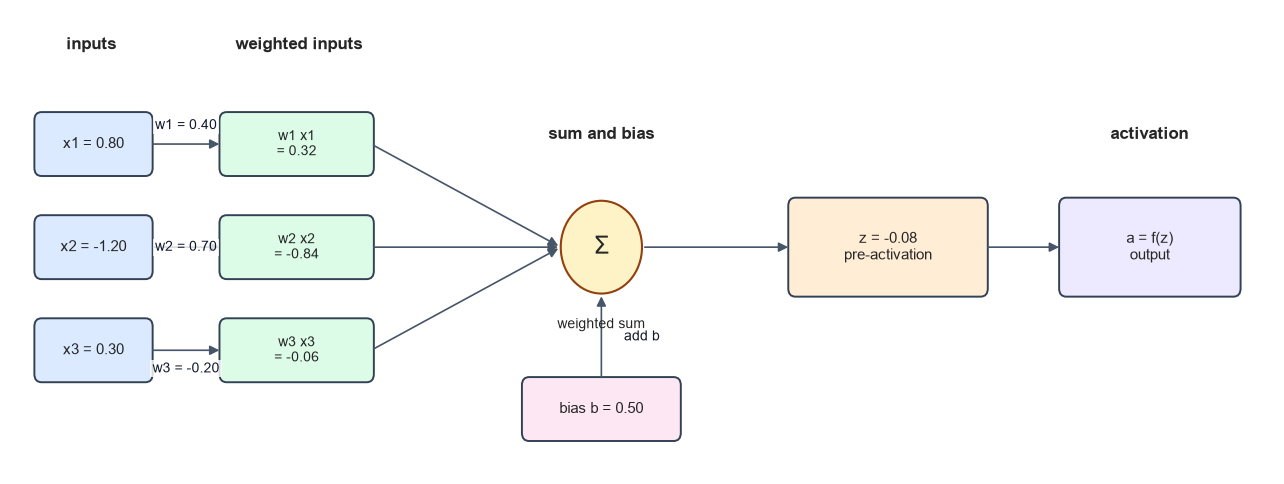

In [66]:


weighted_inputs = x * w

fig, ax = plt.subplots(figsize=(13, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 4.5)
ax.axis("off")

def add_box(x0, y0, width, height, text, facecolor, fontsize=11):
    box = FancyBboxPatch(
        (x0, y0),
        width,
        height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.4,
        edgecolor="#334155",
        facecolor=facecolor,
    )
    ax.add_patch(box)
    ax.text(
        x0 + width / 2,
        y0 + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
    )

def add_arrow(x0, y0, x1, y1, label=None, label_offset=(0, 0)):
    arrow = FancyArrowPatch(
        (x0, y0),
        (x1, y1),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=1.2,
        color="#475569",
    )
    ax.add_patch(arrow)
    if label is not None:
        ax.text(
            (x0 + x1) / 2 + label_offset[0],
            (y0 + y1) / 2 + label_offset[1],
            label,
            ha="center",
            va="center",
            fontsize=10,
            color="#0f172a",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5),
        )

input_y = [3.2, 2.2, 1.2]
for index, y_value in enumerate(input_y):
    add_box(
        0.3,
        y_value - 0.28,
        1.25,
        0.56,
        f"x{index + 1} = {x[index]:.2f}",
        "#dbeafe",
    )
    add_box(
        2.35,
        y_value - 0.28,
        1.65,
        0.56,
        f"w{index + 1} x{index + 1}\n= {weighted_inputs[index]:.2f}",
        "#dcfce7",
        fontsize=10,
    )
    add_arrow(
        1.55,
        y_value,
        2.35,
        y_value,
        label=f"w{index + 1} = {w[index]:.2f}",
        label_offset=(0, 0.18 if index == 0 else -0.18 if index == 2 else 0),
    )
    add_arrow(4.0, y_value, 6.1, 2.2)

sum_node = Circle((6.55, 2.2), 0.45, facecolor="#fef3c7", edgecolor="#92400e", linewidth=1.5)
ax.add_patch(sum_node)
ax.text(6.55, 2.2, "Σ", ha="center", va="center", fontsize=18)
ax.text(6.55, 1.45, "weighted sum", ha="center", va="center", fontsize=10)

add_box(5.7, 0.35, 1.7, 0.56, f"bias b = {b:.2f}", "#fce7f3")
add_arrow(6.55, 0.91, 6.55, 1.75, label="add b", label_offset=(0.45, 0))

add_arrow(7.0, 2.2, 8.65, 2.2)
add_box(8.65, 1.75, 2.15, 0.9, f"z = {z:.2f}\npre-activation", "#ffedd5")
add_arrow(10.8, 2.2, 11.65, 2.2)
add_box(11.65, 1.75, 1.95, 0.9, "a = f(z)\noutput", "#ede9fe")

ax.text(0.9, 4.12, "inputs", ha="center", fontsize=12, fontweight="bold")
ax.text(3.2, 4.12, "weighted inputs", ha="center", fontsize=12, fontweight="bold")
ax.text(6.55, 3.25, "sum and bias", ha="center", fontsize=12, fontweight="bold")
ax.text(12.62, 3.25, "activation", ha="center", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

### Questions

- What is the role of each weight?
- What would happen if one weight became very large?
- Why do we need the bias term?


## 2. Bias experiment

In [67]:
bias_values = [-2.0, 0.0, 2.0]

for b in bias_values:
    z = x @ w + b
    print(f"b = {b:>4}: z = {z:.3f}")


b = -2.0: z = -2.580
b =  0.0: z = -0.580
b =  2.0: z = 1.420


### Interpretation

The bias shifts the neuron response independently of the input values.

For a linear decision boundary:

$$
\mathbf{w}^T\mathbf{x} + b = 0
$$

changing $b$ moves the boundary without changing its orientation.


# Part II — Activation functions

## 3. Implement common activations manually

In [68]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def leaky_relu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * x)


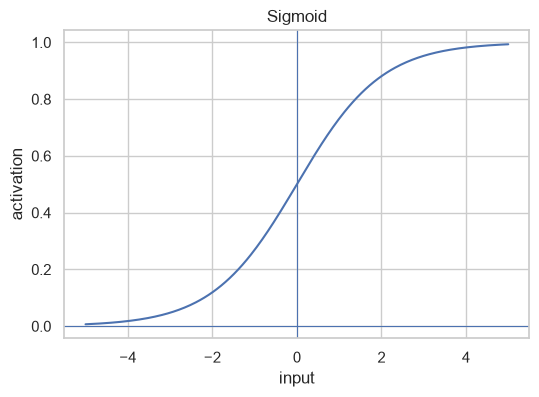

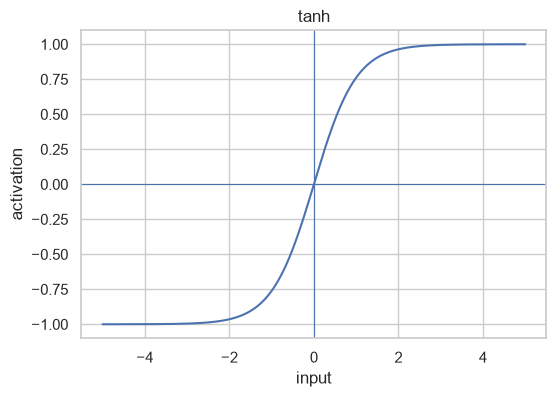

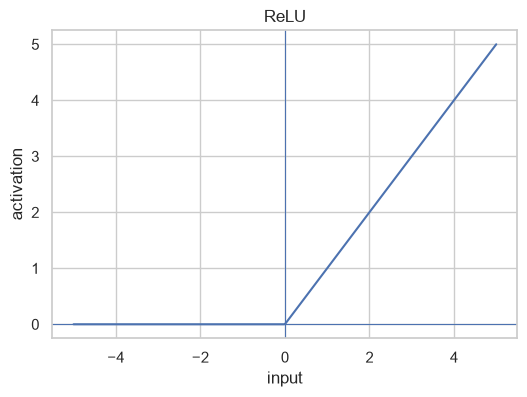

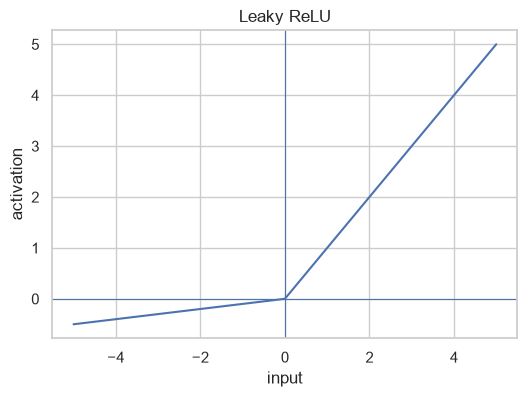

In [69]:
x_grid = np.linspace(-5, 5, 300)

activations = {
    "Sigmoid": sigmoid(x_grid),
    "tanh": tanh(x_grid),
    "ReLU": relu(x_grid),
    "Leaky ReLU": leaky_relu(x_grid)
}

for name, values in activations.items():
    plt.figure(figsize=(6, 4))
    plt.plot(x_grid, values)
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.title(name)
    plt.xlabel("input")
    plt.ylabel("activation")
    plt.show()


# Part III — From one neuron to one dense layer

## 5. Matrix form

A layer with several neurons can be written as:

$$
\mathbf{z} = W\mathbf{x} + \mathbf{b}
$$

Each row of $W$ corresponds to one neuron.


In [70]:
x = np.array([0.8, -1.2, 0.3])

W = np.array([
    [0.2,  0.4, -0.7],
    [0.8, -0.1,  0.3],
    [-0.5, 0.9,  0.2],
    [0.1,  0.4,  0.6]
])

b = np.array([0.1, -0.2, 0.0, 0.3])

z = W @ x + b
tanh_out = tanh(z)


## 6. Dataset description

The student-facing file is week6/large_objects_m0_m1_m2_processed.csv. It was prepared from the microscopy object table before distribution.

Preparation choices:

- Keep rows with image_kind equal to large_object.
- Keep the classic segmentation variant so the same biological object is not represented four times by different segmentation methods.
- Convert the original group labels M0, M1, and M2 to the target values m0, m1, and m2.
- Replace the original experiment identifier with an anonymised sample_group identifier. This is metadata used for leakage-safe splitting, not a predictive feature.
- Retain numerical measurements describing object morphology, geometry, intensity, texture, and chromatin-related properties.
- Remove paths, object names, segmentation-method fields, image metadata, labels, and other identifiers that are not needed for modelling.

The resulting table contains 381 objects, 49 numerical features, 85 sample groups, and the following class counts:

| cell_type | objects |
|---|---:|
| m0 | 132 |
| m1 | 104 |
| m2 | 145 |

Because several objects can originate from the same sample or experiment, observations from one sample_group must not be split between train, validation, and test sets.

In [71]:
from pathlib import Path

DATA_PATH = Path("week6/large_objects_m0_m1_m2_processed.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("large_objects_m0_m1_m2_processed.csv")

df = pd.read_csv(DATA_PATH)

print("Data path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.value_counts())

Data path: large_objects_m0_m1_m2_processed.csv
Shape: (381, 51)


,cell_type,sample_group,volume_voxels,volume_units3,surface_area_units2,sphericity,equivalent_diameter_units,centroid_z,centroid_y,centroid_x,...,surface_to_volume_ratio,equivalent_sphere_radius_units,inertia_eigval_0,inertia_eigval_1,inertia_eigval_2,inertia_anisotropy,centroid_z_norm_stack,centroid_y_norm_stack,centroid_x_norm_stack,distance_to_stack_center_units
0,m0,experiment_001,276743,276743.0,27809.851562,0.738476,80.852355,22.525292,75.822294,84.355601,...,0.100490,40.426177,1478.293368,904.118152,710.562956,0.519336,0.441672,0.486040,0.544230,7.940009
1,m0,experiment_001,283593,283593.0,29347.027344,0.711296,81.514017,25.895449,72.709143,78.685549,...,0.103483,40.757008,1532.955541,1024.523643,651.346833,0.575104,0.488593,0.466084,0.504395,4.936473
2,m0,experiment_001,251874,251874.0,29778.589844,0.647693,78.354072,24.460726,74.602913,77.450868,...,0.118228,39.177036,1627.794318,1089.952015,643.241744,0.604838,0.470399,0.521699,0.499683,3.776818
3,m0,experiment_001,245243,245243.0,29148.757812,0.650023,77.660348,24.147352,91.744735,80.677369,...,0.118857,38.830174,1662.394337,1062.755666,692.584305,0.583381,0.473477,0.588107,0.517163,14.619684
4,m0,experiment_001,282939,282939.0,29995.000000,0.694860,81.451308,23.316542,73.392434,78.215523,...,0.106012,40.725654,1582.797830,969.810146,738.997793,0.533107,0.457187,0.470464,0.501382,4.496454


float64    37
int64      12
object      2
Name: count, dtype: int64

## Universal biological data-preparation checklist

Use this checklist before starting the neural-network analysis. Tick an item only after inspecting the data or documenting a justified decision.

### Scientific purpose and provenance

- [X] Is the biological question and prediction task stated clearly?
- [X] Is the unit of observation clear: here, one row should represent one large microscopy object?
- [X] Do I know where the data came from and how the measurements were generated?
- [X] Have I recorded the data version, preprocessing history, and transformations already applied?

### Table shape and identifiers

- [X] Is the table tidy: one observation per row, one variable per column, and one value per cell?
- [X] If the original assay had features in rows and samples in columns, was it transposed into the format expected by the analysis tool?
- [ ] Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns?
- [ ] Can every feature and observation be traced back to its source?
- [ ] Are the feature matrix and metadata aligned by an explicit identifier rather than by row order?


In [72]:

display(pd.Series(df.columns, name="column"))


display(df.dtypes.rename("dtype").to_frame())


display(df.isna().sum().sort_values(ascending=False).head(15).rename("missing").to_frame())


for column in ["cell_type", "sample_group"]:
    print(f"{column}: {df[column].nunique()} unique values")
    display(df[column].value_counts(dropna=False).rename("count").to_frame())

0                            cell_type
1                         sample_group
2                        volume_voxels
3                        volume_units3
4                  surface_area_units2
5                           sphericity
6            equivalent_diameter_units
7                           centroid_z
8                           centroid_y
9                           centroid_x
10                             bbox_z0
11                             bbox_y0
12                             bbox_x0
13                             bbox_z1
14                             bbox_y1
15                             bbox_x1
16                        bbox_depth_z
17                       bbox_height_y
18                        bbox_width_x
19                  bbox_volume_voxels
20                  bbox_fill_fraction
21                      mean_intensity
22                    median_intensity
23                       min_intensity
24                       max_intensity
25                       

,dtype
cell_type,object
sample_group,object
volume_voxels,int64
volume_units3,float64
surface_area_units2,float64
sphericity,float64
equivalent_diameter_units,float64
centroid_z,float64
centroid_y,float64
centroid_x,float64


,missing
surface_area_units2,13
sphericity,13
surface_to_volume_ratio,13
projected_circularity,13
cell_type,0
projected_perimeter_px,0
intensity_p90,0
integrated_intensity,0
intensity_cv,0
chromatin_condensation_parameter,0


cell_type: 3 unique values


,count
cell_type,
m2,145
m0,132
m1,104


sample_group: 85 unique values


,count
sample_group,
experiment_004,22
experiment_071,22
experiment_080,14
experiment_001,13
experiment_081,13
...,...
experiment_025,1
experiment_059,1
experiment_060,1



### Types, values, and measurement meaning

- [X] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [X] Are units, scales, encodings, reference categories, and detection limits understood?
- [X] Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values?
- [X] Are normalization, scaling, log transformation, and batch-correction steps documented?

### Missing values

- [X] Have I detected missing values using the dataset's actual missing-value representations, not only NaN?
- [X] Have I measured missingness by row, column, group, and relevant batch or time variable?
- [X] Do I know whether missingness is structural, technical, or plausibly related to the biology or target?
- [X] Have I justified whether to retain, remove, or impute missing values?
- [ ] If imputing, will the imputer be fitted on training data only and then applied to validation and test data?


In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 51 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   cell_type                         381 non-null    object 
 1   sample_group                      381 non-null    object 
 2   volume_voxels                     381 non-null    int64  
 3   volume_units3                     381 non-null    float64
 4   surface_area_units2               368 non-null    float64
 5   sphericity                        368 non-null    float64
 6   equivalent_diameter_units         381 non-null    float64
 7   centroid_z                        381 non-null    float64
 8   centroid_y                        381 non-null    float64
 9   centroid_x                        381 non-null    float64
 10  bbox_z0                           381 non-null    int64  
 11  bbox_y0                           381 non-null    int64  
 12  bbox_x0 

In [74]:
display(df.describe().T)


display(df.isna().sum().sort_values(ascending=False).head(15).rename("missing").to_frame())


,count,mean,std,min,25%,50%,75%,max
volume_voxels,381.0,8.112129e+05,4.128121e+06,1.772930e+05,3.000220e+05,3.762040e+05,5.310970e+05,6.180274e+07
volume_units3,381.0,8.112129e+05,4.128121e+06,1.772930e+05,3.000220e+05,3.762040e+05,5.310970e+05,6.180274e+07
surface_area_units2,368.0,4.781240e+04,2.956593e+04,1.940683e+04,3.071611e+04,3.833912e+04,5.163522e+04,1.922112e+05
sphericity,368.0,6.468251e-01,1.049543e-01,3.452301e-01,5.690141e-01,6.565045e-01,7.210297e-01,8.586280e-01
equivalent_diameter_units,381.0,9.682969e+01,3.396765e+01,6.969971e+01,8.305864e+01,8.956567e+01,1.004751e+02,4.905347e+02
centroid_z,381.0,2.792631e+01,5.114021e+00,1.600000e+01,2.471158e+01,2.758301e+01,3.031702e+01,4.844828e+01
centroid_y,381.0,1.063140e+02,4.846952e+01,3.900000e+01,7.939970e+01,9.248645e+01,1.171447e+02,5.275000e+02
centroid_x,381.0,1.042225e+02,4.271740e+01,3.000000e+01,7.914662e+01,9.122094e+01,1.140194e+02,4.215000e+02
bbox_z0,381.0,7.669291e+00,4.182775e+00,0.000000e+00,6.000000e+00,7.000000e+00,9.000000e+00,3.200000e+01
bbox_y0,381.0,2.770604e+01,2.135163e+01,0.000000e+00,1.500000e+01,2.200000e+01,3.400000e+01,1.960000e+02


,missing
surface_area_units2,13
sphericity,13
surface_to_volume_ratio,13
projected_circularity,13
cell_type,0
projected_perimeter_px,0
intensity_p90,0
integrated_intensity,0
intensity_cv,0
chromatin_condensation_parameter,0


In [75]:

constant_features = [column for column in df.columns if df[column].nunique(dropna=False) <= 1]
constant_features


[]

In [76]:

display(df['cell_type'].value_counts().sort_index().rename("objects").to_frame())
display(df['sample_group'].value_counts().to_frame("objects_per_group"))

,objects
cell_type,
m0,132
m1,104
m2,145


,objects_per_group
sample_group,
experiment_004,22
experiment_071,22
experiment_080,14
experiment_001,13
experiment_081,13
...,...
experiment_025,1
experiment_059,1
experiment_060,1


In [77]:
candidate_features = df.select_dtypes(include=np.number).columns.tolist()

print("Candidate numerical features:", len(candidate_features))
print(candidate_features[:10])

Candidate numerical features: 49
['volume_voxels', 'volume_units3', 'surface_area_units2', 'sphericity', 'equivalent_diameter_units', 'centroid_z', 'centroid_y', 'centroid_x', 'bbox_z0', 'bbox_y0']



### Replicates, dependence, and grouping

- [X] Have I checked for exact duplicates and near-duplicate observations?
- [X] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [X] Is the independent biological unit identified by a grouping variable?
- [X] Will all related observations and their derivatives remain in the same train, validation, and test split?
- [ ] If augmented or synthetic observations were created, is their provenance recorded and reproducible?

### Target, leakage, and study design

- [X] Is the target defined before modelling, with its classes checked for balance and validity?
- [ ] Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features?
- [ ] Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders?
- [ ] Have I checked whether the target is associated with a technical or grouping variable?
- [ ] Does the planned split represent the biological generalization question?


In [78]:
candidate_features = df.select_dtypes(include=np.number).columns.tolist()

print("Candidate numerical features:", len(candidate_features))
print(candidate_features[:10])

Candidate numerical features: 49
['volume_voxels', 'volume_units3', 'surface_area_units2', 'sphericity', 'equivalent_diameter_units', 'centroid_z', 'centroid_y', 'centroid_x', 'bbox_z0', 'bbox_y0']



### Reproducibility and decision record

- [X] Are random seeds, software versions, file names, and input/output shapes recorded?
- [X] Are all preprocessing steps placed in a reproducible pipeline?
- [X] Have I recorded unresolved data-quality concerns and the decisions made about them?
- [X] Can another person explain what each row, column, feature, target, and grouping variable means?


## 8. Small exploratory data analysis

Before splitting or fitting a model, inspect the target balance, group sizes, and several representative feature distributions. These plots are for exploration, not feature selection.

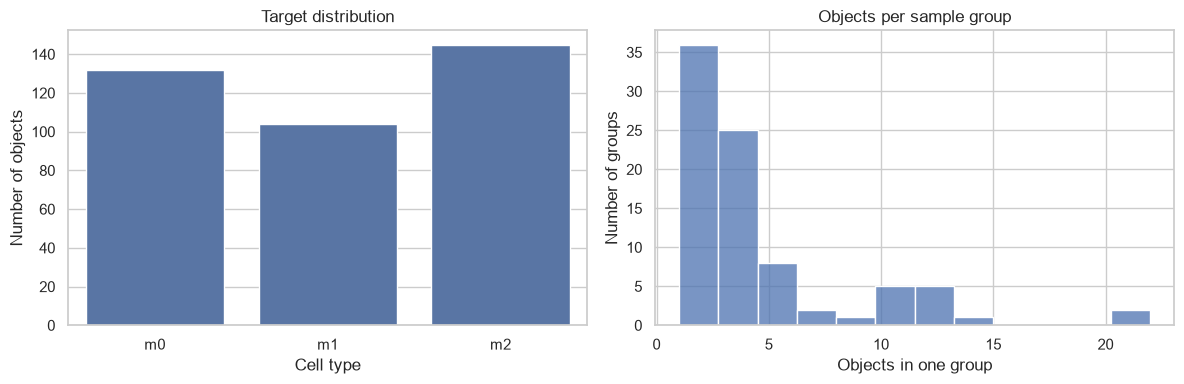

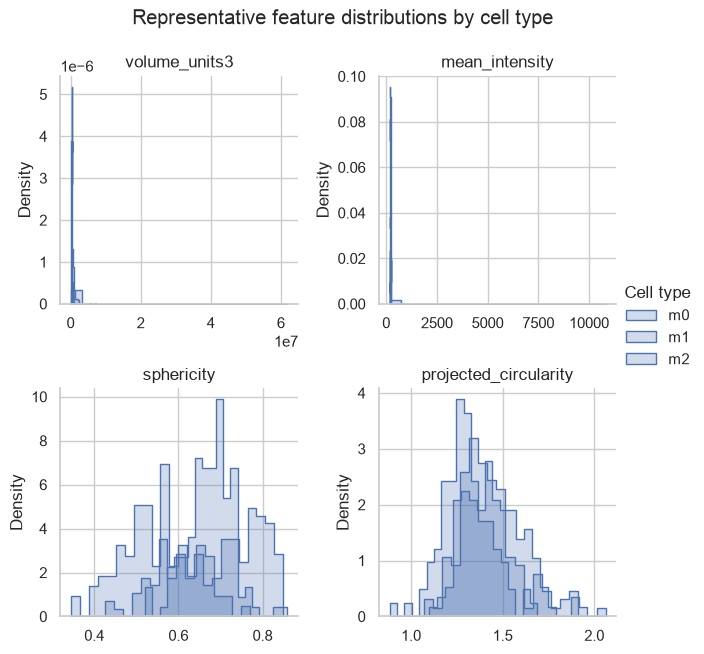

In [79]:
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plot_features = [
    column for column in [
        "volume_units3",
        "mean_intensity",
        "sphericity",
        "projected_circularity",
    ]
    if column in df.columns
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="cell_type",
    order=["m0", "m1", "m2"],
    ax=axes[0],
)
axes[0].set_title("Target distribution")
axes[0].set_xlabel("Cell type")
axes[0].set_ylabel("Number of objects")

group_sizes = df["sample_group"].value_counts()
sns.histplot(group_sizes, bins=12, ax=axes[1])
axes[1].set_title("Objects per sample group")
axes[1].set_xlabel("Objects in one group")
axes[1].set_ylabel("Number of groups")

plt.tight_layout()
plt.show()

if plot_features:
    long_features = df.melt(
        id_vars=["cell_type"],
        value_vars=plot_features,
        var_name="feature",
        value_name="value",
    )
    g = sns.FacetGrid(
        long_features,
        col="feature",
        col_wrap=2,
        hue="cell_type",
        sharex=False,
        sharey=False,
        height=3.2,
    )
    g.map_dataframe(
        sns.histplot,
        bins=20,
        element="step",
        stat="density",
        common_norm=False,
    )
    g.add_legend(title="Cell type")
    g.set_titles("{col_name}")
    g.fig.suptitle("Representative feature distributions by cell type", y=1.02)
    plt.show()

## 9. Association between the target and numerical features

The target is categorical, while the predictors are numerical. Two descriptive measures are useful:

- Mutual information estimates how much information a feature contains about the cell-type label.
- Eta squared measures the fraction of feature variance explained by differences between target groups.

For a feature X and target Y:

$$
I(X;Y)
=
\sum_{x,y}
p(x,y)
\log
\left(
\frac{p(x,y)}{p(x)p(y)}
\right)
$$

The formula compares the observed joint distribution with the distribution expected if X and Y were independent.

- If X and Y are independent, mutual information is 0.
- Larger values indicate stronger statistical dependence.
- Mutual information is not directional and does not prove biological causation.

These statistics are exploratory. They are not used as a substitute for group-aware evaluation.

,feature,eta_squared,mutual_information
0,bbox_y1,0.198766,0.393736
1,centroid_y,0.234275,0.383773
2,inertia_eigval_1,0.025528,0.377478
3,centroid_x,0.322398,0.357841
4,bbox_x1,0.306146,0.357505
5,inertia_eigval_0,0.022391,0.345199
6,chromatin_inner_area_px,0.023219,0.319404
7,surface_area_units2,0.402473,0.315076
8,projected_perimeter_px,0.356575,0.313204
9,projected_area_units2,0.026228,0.303000


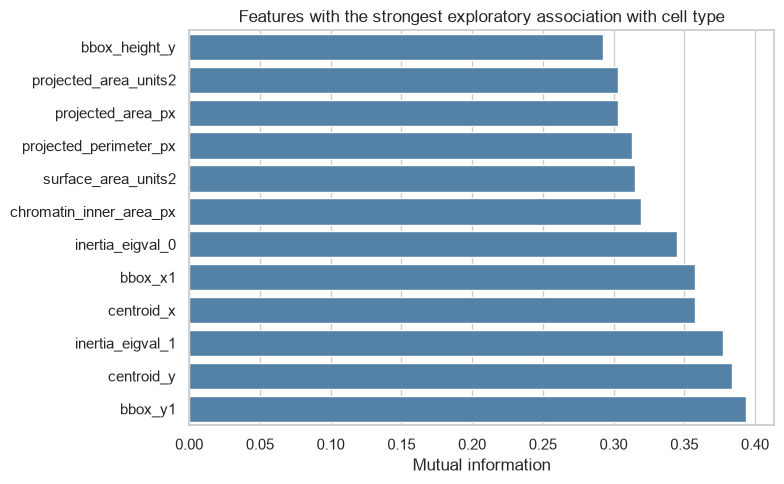

In [80]:
from sklearn.feature_selection import mutual_info_classif

association_rows = []
target_codes = df["cell_type"].map({"m0": 0, "m1": 1, "m2": 2})

for feature in candidate_features:
    values = df[feature]
    valid = values.notna() & target_codes.notna()
    feature_values = values[valid].to_numpy()
    feature_target = target_codes[valid].to_numpy()

    if len(feature_values) < 3 or np.isclose(np.var(feature_values), 0):
        eta_squared = np.nan
        mutual_information = 0.0
    else:
        grand_mean = feature_values.mean()
        grouped = pd.DataFrame({
            "value": feature_values,
            "target": feature_target,
        }).groupby("target")["value"]
        group_means = grouped.mean()
        group_counts = grouped.size()
        ss_between = ((group_means - grand_mean) ** 2 * group_counts).sum()
        ss_total = ((feature_values - grand_mean) ** 2).sum()
        eta_squared = ss_between / ss_total if ss_total > 0 else np.nan

        mutual_information = mutual_info_classif(
            pd.DataFrame({feature: feature_values}),
            feature_target,
            random_state=RANDOM_STATE,
        )[0]

    association_rows.append({
        "feature": feature,
        "eta_squared": eta_squared,
        "mutual_information": mutual_information,
    })

association = (
    pd.DataFrame(association_rows)
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)

display(association.head(15))

top_association = association.head(12).sort_values("mutual_information")
plt.figure(figsize=(8, 5))
sns.barplot(
    data=top_association,
    x="mutual_information",
    y="feature",
    color="steelblue",
)
plt.title("Features with the strongest exploratory association with cell type")
plt.xlabel("Mutual information")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 10. Define feature columns and metadata

The processed table has only two non-feature columns:

- cell_type: the classification target.
- sample_group: an anonymised sample/experiment grouping variable.

All remaining columns are numerical measurements and can be used as model inputs. The group column is kept separately so related observations can remain in the same data split.

In [81]:
TARGET = "cell_type"
GROUP_COLUMN = "sample_group"
META_COLUMNS = [TARGET, GROUP_COLUMN]

feature_cols = [column for column in df.columns if column not in META_COLUMNS]
X = df[feature_cols].copy()
y = df[TARGET].copy()
groups = df[GROUP_COLUMN].copy()

print("Number of features:", len(feature_cols))
print("Feature matrix shape:", X.shape)
print("Target values:", sorted(y.unique()))
print("Number of sample groups:", groups.nunique())

Number of features: 49
Feature matrix shape: (381, 49)
Target values: ['m0', 'm1', 'm2']
Number of sample groups: 85


## 12. Create a reproducible stratified group-aware test split

Cells from the same biological sample or experiment are not independent. At the same time, a random choice of groups can produce an unusually unbalanced test set.

We use `StratifiedGroupKFold` to satisfy both requirements:

- every group stays entirely in one partition;
- the class proportions are kept approximately similar across folds;
- shuffling and the fixed random seed make the split reproducible.

We select one of five outer folds as the test set. The selection is based only on split quality: test-size closeness to 20% and similarity to the overall class proportions.

In [82]:
def split_quality(test_indices, y_values, target_fraction):
    overall_proportions = y_values.value_counts(normalize=True).sort_index()
    test_proportions = (
        y_values.iloc[test_indices]
        .value_counts(normalize=True)
        .reindex(overall_proportions.index)
        .fillna(0)
    )
    size_error = abs(len(test_indices) / len(y_values) - target_fraction)
    class_error = np.abs(test_proportions - overall_proportions).sum()
    return size_error + class_error


outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
outer_splits = list(outer_splitter.split(X, y, groups=groups))

outer_fold_index = min(
    range(len(outer_splits)),
    key=lambda index: split_quality(
        outer_splits[index][1],
        y,
        target_fraction=0.20,
    ),
)
train_idx, test_idx = outer_splits[outer_fold_index]

X_train_full = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train_full = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train_full = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

shared_groups = set(groups_train_full).intersection(groups_test)

print("Selected outer fold:", outer_fold_index)
print("Training objects:", len(X_train_full))
print("Test objects:", len(X_test))
print("Training groups:", groups_train_full.nunique())
print("Test groups:", groups_test.nunique())
print("Shared groups:", len(shared_groups))
print("Overall class proportions:")
print(y.value_counts(normalize=True).sort_index())
print("Test class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

assert len(shared_groups) == 0
assert set(y_test.unique()) == set(y.unique())

Selected outer fold: 0
Training objects: 305
Test objects: 76
Training groups: 69
Test groups: 16
Shared groups: 0
Overall class proportions:
cell_type
m0    0.346457
m1    0.272966
m2    0.380577
Name: proportion, dtype: float64
Test class proportions:
cell_type
m0    0.342105
m1    0.276316
m2    0.381579
Name: proportion, dtype: float64


## 13. Create a stratified group-aware validation split

The validation set is created only from the training portion. It is also stratified by class and separated by group, so it can be used for early stopping and model selection without touching the final test set.

In [83]:
inner_splitter = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)
inner_splits = list(
    inner_splitter.split(
        X_train_full,
        y_train_full,
        groups=groups_train_full,
    )
)

inner_fold_index = min(
    range(len(inner_splits)),
    key=lambda index: split_quality(
        inner_splits[index][1],
        y_train_full,
        target_fraction=0.25,
    ),
)
train_idx2, val_idx = inner_splits[inner_fold_index]

X_train = X_train_full.iloc[train_idx2].copy()
X_val = X_train_full.iloc[val_idx].copy()
y_train = y_train_full.iloc[train_idx2].copy()
y_val = y_train_full.iloc[val_idx].copy()
groups_train = groups_train_full.iloc[train_idx2].copy()
groups_val = groups_train_full.iloc[val_idx].copy()

shared_train_val_groups = set(groups_train).intersection(groups_val)

print("Selected inner fold:", inner_fold_index)
print("Training objects:", len(X_train))
print("Validation objects:", len(X_val))
print("Training groups:", groups_train.nunique())
print("Validation groups:", groups_val.nunique())
print("Shared train/validation groups:", len(shared_train_val_groups))
print("Training class proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("Validation class proportions:")
print(y_val.value_counts(normalize=True).sort_index())

assert len(shared_train_val_groups) == 0
assert set(y_val.unique()) == set(y.unique())

Selected inner fold: 0
Training objects: 227
Validation objects: 78
Training groups: 52
Validation groups: 17
Shared train/validation groups: 0
Training class proportions:
cell_type
m0    0.348018
m1    0.273128
m2    0.378855
Name: proportion, dtype: float64
Validation class proportions:
cell_type
m0    0.346154
m1    0.269231
m2    0.384615
Name: proportion, dtype: float64


# Part VI — Scaling

## 14. Impute and standardize features

The inspection showed missing values in some derived geometry features. We will retain those rows and impute missing feature values with the training-set median.

Both the imputer and the scaler are fitted on training data only. The validation and test sets are transformed using those fitted objects, preventing information from those sets from influencing preprocessing.

In [84]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Missing values before imputation:")
print("train:", int(X_train.isna().sum().sum()))
print("validation:", int(X_val.isna().sum().sum()))
print("test:", int(X_test.isna().sum().sum()))

print("Scaled shapes:")
print("train:", X_train_scaled.shape)
print("validation:", X_val_scaled.shape)
print("test:", X_test_scaled.shape)
print("Missing values after imputation:", int(np.isnan(X_train_scaled).sum()))
print("First five training means:", X_train_scaled.mean(axis=0)[:5])
print("First five training standard deviations:", X_train_scaled.std(axis=0)[:5])

Missing values before imputation:
train: 8
validation: 8
test: 36
Scaled shapes:
train: (227, 49)
validation: (78, 49)
test: (76, 49)
Missing values after imputation: 0
First five training means: [ 9.78170066e-18  9.78170066e-18 -7.82536053e-17 -7.90361413e-16
  9.31217903e-16]
First five training standard deviations: [1. 1. 1. 1. 1.]


## Exploratory t-SNE visualization

The following plot provides a two-dimensional visual summary of the processed feature space. Points are coloured by cell type.

t-SNE is used here only for exploration. It is not a predictive model, and the embedding should not be used to evaluate the classifier or replace group-aware splitting.

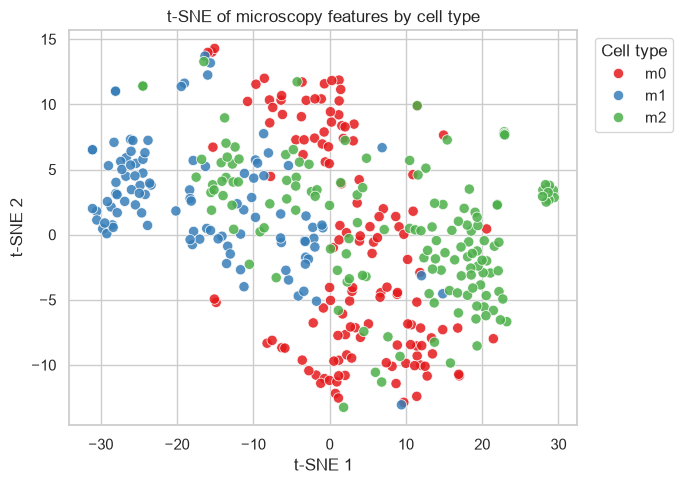

In [85]:

X_all_scaled = scaler.transform(imputer.transform(X))

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_all_scaled)

tsne_plot = pd.DataFrame({
    "TSNE1": X_tsne[:, 0],
    "TSNE2": X_tsne[:, 1],
    "cell_type": y.to_numpy(),
})

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=tsne_plot,
    x="TSNE1",
    y="TSNE2",
    hue="cell_type",
    hue_order=["m0", "m1", "m2"],
    palette="Set1",
    s=55,
    alpha=0.85,
)
plt.title("t-SNE of microscopy features by cell type")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Part VII — Convert data to PyTorch tensors

In [86]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

class_names = sorted(y.unique())
class_to_index = {name: index for index, name in enumerate(class_names)}

y_train_t = torch.tensor(
    y_train.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_val_t = torch.tensor(
    y_val.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_test_t = torch.tensor(
    y_test.map(class_to_index).to_numpy(),
    dtype=torch.long,
)

print("Class mapping:", class_to_index)
print("Training tensor shapes:", X_train_t.shape, y_train_t.shape)
print("Validation tensor shapes:", X_val_t.shape, y_val_t.shape)
print("Test tensor shapes:", X_test_t.shape, y_test_t.shape)

Class mapping: {'m0': 0, 'm1': 1, 'm2': 2}
Training tensor shapes: torch.Size([227, 49]) torch.Size([227])
Validation tensor shapes: torch.Size([78, 49]) torch.Size([78])
Test tensor shapes: torch.Size([76, 49]) torch.Size([76])


In [87]:
y_test_t

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2])

## 16. Create Dataset and DataLoader objects

In [88]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 8
Validation batches: 3
Test batches: 3


# Part VIII — First MLP

## 17. Define a simple network

Suggested starting architecture:

$$
p \rightarrow 32 \rightarrow 16 \rightarrow K
$$

where:

- $p$ = number of input features
- $K$ = number of classes


In [89]:
class MLP(nn.Module):
    def __init__(self, input_dim, n_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, n_classes)
        )

    def forward(self, x):
        return self.network(x)


In [90]:
input_dim = X_train_scaled.shape[1]
n_classes = len(class_names)

model = MLP(
    input_dim=input_dim,
    n_classes=n_classes,
).to(DEVICE)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=49, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


## 18. Visualise the mMLP with torchview

The graph is generated from the actual PyTorch model, so it reflects the layers used in training. Tensor shapes make the transition from a batch of 49 microscopy features to three class logits explicit.


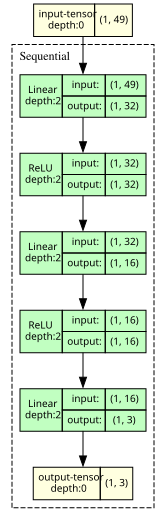

In [91]:
import shutil
from torchview import draw_graph

sample_input = torch.zeros((1, input_dim), dtype=torch.float32, device=DEVICE)
model_graph = draw_graph(
    model,
    input_data=sample_input,
    expand_nested=True,
    graph_name="microscopy_mlp",
)

if shutil.which("dot") is not None:
    # The Python graphviz package uses the Graphviz `dot` executable to
    # render this structural graph as an image in Jupyter.
    display(model_graph.visual_graph)
else:
    # torchview still created the graph; show its DOT source without raising
    # an error when only the Python package is installed.
    print("Graphviz executable not found. Install Graphviz and reopen the notebook to render the image.")
    print("The torchview DOT source was generated successfully:")
    print(model_graph.visual_graph.source)

## 19. Count trainable parameters

In [92]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("Trainable parameters:", count_parameters(model))


Trainable parameters: 2179


### Manual check

For:

```text
input_dim → 32 → 16 → K
```

calculate the parameter count manually before comparing with PyTorch.


# Part IX — Logits and loss

## 20. What does the model output?

For multiclass classification, the last layer outputs **logits**.

Do not add `Softmax()` inside the model when using:

```python
nn.CrossEntropyLoss()
```

because `CrossEntropyLoss` already handles the required transformation internally.


In [93]:
criterion = nn.CrossEntropyLoss()

with torch.no_grad():
    logits = model(X_train_t[:5].to(DEVICE))
    probabilities = torch.softmax(logits, dim=1)

print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)
print("Probabilities:")
display(probabilities.cpu().numpy())
print("Probability sums:", probabilities.sum(dim=1).cpu().numpy())

Logits shape: torch.Size([5, 3])
Probabilities shape: torch.Size([5, 3])
Probabilities:


array([[0.36189038, 0.34712705, 0.29098263],
       [0.37126368, 0.3454677 , 0.28326857],
       [0.37033245, 0.33691788, 0.29274958],
       [0.35457018, 0.34976077, 0.29566902],
       [0.37909147, 0.34151652, 0.27939203]], dtype=float32)

Probability sums: [1.         0.99999994 0.99999994 0.99999994 1.        ]


# Part X — Training loop

## 21. The five central lines

```python
optimizer.zero_grad()
pred = model(X_batch)
loss = criterion(pred, y_batch)
loss.backward()
optimizer.step()
```

These implement:

$$
forward \rightarrow loss \rightarrow gradients \rightarrow update
$$


In [94]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 22. Training function

In [95]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


## 23. Validation function

In [96]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


## 24. Full training loop

In [97]:
N_EPOCHS = 100

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(N_EPOCHS):
     train_loss, train_acc = train_one_epoch(
         model,
         train_loader,
         criterion,
         optimizer,
         DEVICE)

     val_loss, val_acc = evaluate(
         model,
         val_loader,
         criterion,
         DEVICE)

     history["train_loss"].append(train_loss)
     history["val_loss"].append(val_loss)
     history["train_acc"].append(train_acc)
     history["val_acc"].append(val_acc)

     if (epoch + 1) % 5 == 0:
         print(
             f"Epoch {epoch+1:03d} | "
             f"train loss={train_loss:.4f} | "
             f"val loss={val_loss:.4f} | "
             f"train acc={train_acc:.3f} | "
             f"val acc={val_acc:.3f}")


Epoch 005 | train loss=0.9045 | val loss=1.3871 | train acc=0.661 | val acc=0.731
Epoch 010 | train loss=0.7368 | val loss=2.5432 | train acc=0.639 | val acc=0.705
Epoch 015 | train loss=0.6522 | val loss=2.9976 | train acc=0.692 | val acc=0.718
Epoch 020 | train loss=0.5777 | val loss=3.2725 | train acc=0.749 | val acc=0.731
Epoch 025 | train loss=0.5001 | val loss=3.4398 | train acc=0.797 | val acc=0.769
Epoch 030 | train loss=0.4288 | val loss=4.2840 | train acc=0.819 | val acc=0.782
Epoch 035 | train loss=0.3597 | val loss=5.0755 | train acc=0.890 | val acc=0.744
Epoch 040 | train loss=0.3093 | val loss=6.1148 | train acc=0.903 | val acc=0.795
Epoch 045 | train loss=0.2691 | val loss=5.6637 | train acc=0.930 | val acc=0.782
Epoch 050 | train loss=0.2330 | val loss=7.2934 | train acc=0.930 | val acc=0.795
Epoch 055 | train loss=0.2103 | val loss=7.6174 | train acc=0.943 | val acc=0.808
Epoch 060 | train loss=0.1832 | val loss=8.7769 | train acc=0.956 | val acc=0.782
Epoch 065 | trai

## 25. Plot learning curves

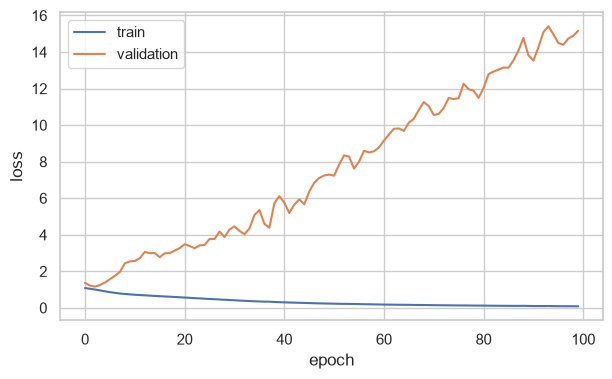

In [98]:
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()


## Tracking experiments with a local MLflow server

Notebook output is useful while we work, but it is difficult to compare after several training runs. MLflow stores parameters, metrics, figures, and model artifacts in a searchable experiment database.

For this practical, start the MLflow server in a **separate terminal from the project root** before running the code cell below:

```text
uv run mlflow server --host 127.0.0.1 --port 5000 --workers 1 --backend-store-uri sqlite:///week6/mlflow.db --allowed-hosts localhost,127.0.0.1,localhost:5000,127.0.0.1:5000
```

Then open `http://127.0.0.1:5000` in a browser. The notebook connects to this local server through its HTTP API; it does not create or manage the database itself. The database and artifact directory are local teaching files and should not be committed to GitHub.

In the following cell we log:

- model and training parameters;
- metrics at every epoch;
- a learning-curve figure;
- a CPU-compatible PyTorch `state_dict` artifact.


🏃 View run pytorch-baseline at: http://127.0.0.1:5000/#/experiments/1/runs/4570cd71c0ac43dca9715ad42b6cc0c5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


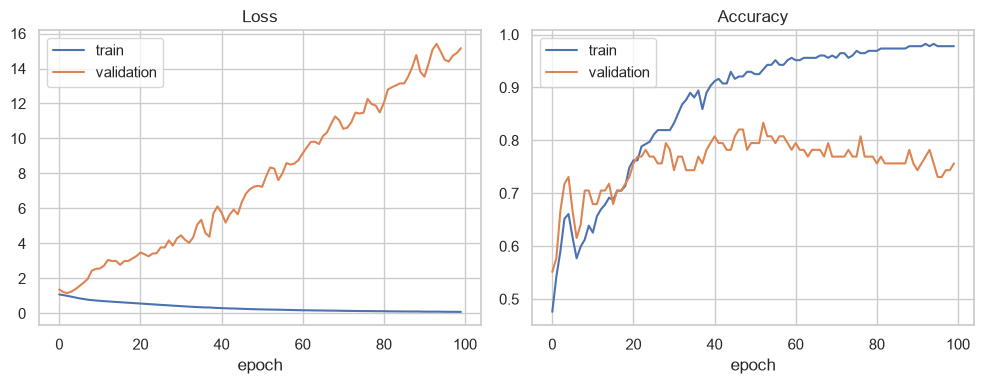

MLflow tracking URI: http://127.0.0.1:5000
MLflow baseline run ID: 4570cd71c0ac43dca9715ad42b6cc0c5


In [99]:
import os
import tempfile
from pathlib import Path

import sys
import importlib

# Positron can expose its own typing_extensions before the project environment.
# MLflow/FastAPI needs the newer sentinel symbol, so prioritize this project's
# site-packages before importing MLflow.
project_roots = [Path.cwd(), *Path.cwd().parents]
def venv_site_packages(root):
    # Windows layout: .venv/Lib/site-packages; macOS/Linux layout: .venv/lib/pythonX.Y/site-packages
    candidates = [root / ".venv" / "Lib" / "site-packages", *sorted((root / ".venv" / "lib").glob("python*/site-packages"))]
    return next((c for c in candidates if c.exists()), None)

project_root = next((root for root in project_roots if venv_site_packages(root) is not None), None)
if project_root is None:
    raise RuntimeError(
        "Could not locate the practicals .venv. Select the project kernel or run the notebook from the project directory."
    )

project_site_packages = str(venv_site_packages(project_root))
if project_site_packages not in sys.path:
    sys.path.insert(0, project_site_packages)

loaded_typing_extensions = sys.modules.get("typing_extensions")
if loaded_typing_extensions is not None and not hasattr(loaded_typing_extensions, "sentinel"):
    del sys.modules["typing_extensions"]
    importlib.invalidate_caches()

import typing_extensions
if not hasattr(typing_extensions, "sentinel"):
    raise RuntimeError(
        f"The active kernel is using an incompatible typing_extensions package: {typing_extensions.__file__}"
    )

import mlflow

tracking_uri = os.environ.get("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment("week6-microscopy-mlp")


def make_training_figure(series):
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(series["train_loss"], label="train")
    axes[0].plot(series["validation_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[1].plot(series["train_accuracy"], label="train")
    axes[1].plot(series["validation_accuracy"], label="validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    figure.tight_layout()
    return figure


def log_mlflow_training_run(
    run_name,
    params,
    series=None,
    final_metrics=None,
    model=None,
    model_type=None,
    figure=None,
):
    """Log one comparable experiment to the local MLflow server."""
    params = dict(params)
    if model_type is not None:
        params["model_type"] = model_type

    with mlflow.start_run(run_name=run_name) as active_run:
        mlflow.log_params(params)

        if series:
            for metric_name, values in series.items():
                for epoch, value in enumerate(values, start=1):
                    mlflow.log_metric(metric_name, float(value), step=epoch)

        if final_metrics:
            mlflow.log_metrics({
                name: float(value)
                for name, value in final_metrics.items()
            })

        if figure is not None:
            mlflow.log_figure(figure, "training_curves.png")

        if isinstance(model, (str, Path)):
            # model was trained in a worker process and saved to this file
            mlflow.log_artifact(str(model), artifact_path="model")
        elif model is not None:
            with tempfile.TemporaryDirectory() as temporary_directory:
                temporary_directory = Path(temporary_directory)
                if model_type == "pytorch":
                    artifact_file = temporary_directory / "pytorch_state_dict.pt"
                    torch.save(
                        copy.deepcopy(model).to("cpu").state_dict(),
                        artifact_file,
                    )
                elif model_type == "keras":
                    artifact_file = temporary_directory / "keras_model.keras"
                    model.save(artifact_file)
                elif model_type == "xgboost":
                    artifact_file = temporary_directory / "xgboost_model.json"
                    model.save_model(str(artifact_file))
                else:
                    raise ValueError(f"Unsupported model_type: {model_type}")
                mlflow.log_artifact(str(artifact_file), artifact_path="model")

        return active_run.info.run_id


baseline_series = {
    "train_loss": history["train_loss"],
    "validation_loss": history["val_loss"],
    "train_accuracy": history["train_acc"],
    "validation_accuracy": history["val_acc"],
}
baseline_figure = make_training_figure(baseline_series)
baseline_run_id = log_mlflow_training_run(
    run_name="pytorch-baseline",
    params={
        "framework": "pytorch",
        "input_dim": input_dim,
        "hidden_layers": "32,16",
        "n_classes": n_classes,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "epochs": len(history["train_loss"]),
        "batch_size": BATCH_SIZE,
        "random_state": RANDOM_STATE,
    },
    series=baseline_series,
    final_metrics={
        "final_validation_loss": history["val_loss"][-1],
        "final_validation_accuracy": history["val_acc"][-1],
        "best_validation_accuracy": max(history["val_acc"]),
    },
    model=model,
    model_type="pytorch",
    figure=baseline_figure,
)
plt.show()
plt.close(baseline_figure)
print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow baseline run ID:", baseline_run_id)


# Part XI — Inspect gradients

## 26. Gradient norms

After `loss.backward()`, every trainable parameter should usually have a gradient.

Inspect gradient magnitude.


In [100]:


for name, param in model.named_parameters():
     if param.grad is not None:
         print(name, tuple(param.shape), param.grad.norm().item())


network.0.weight (32, 49) 1.6831748485565186
network.0.bias (32,) 0.5307906866073608
network.2.weight (16, 32) 0.9804710745811462
network.2.bias (16,) 0.27355504035949707
network.4.weight (3, 16) 0.8199417591094971
network.4.bias (3,) 0.17573410272598267


### Questions

- What would gradients close to zero imply?
- What would extremely large gradients suggest?
- How might activation choice affect this?


# Part XII — Learning-rate experiment

## 27. Train identical models with different learning rates

Suggested values:

```python
1e-5
1e-3
1e-1
```

Keep everything else identical.


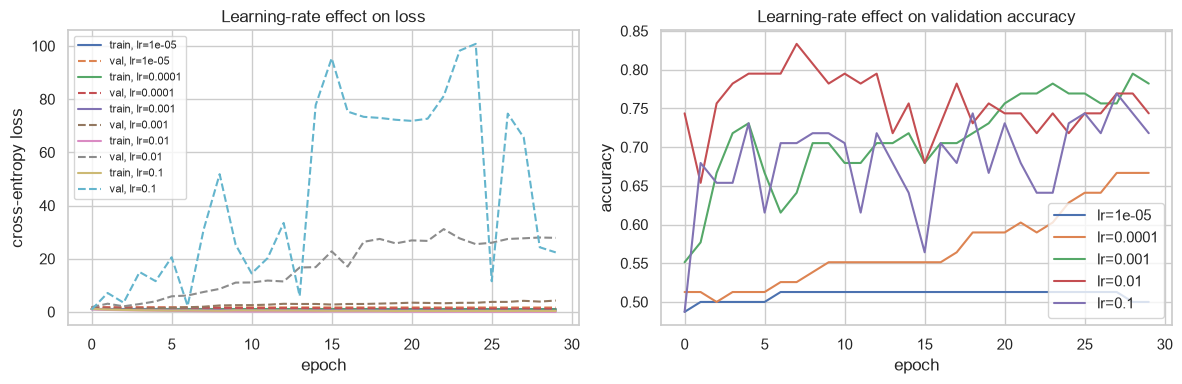

🏃 View run mlp-learning-rate-1e-05 at: http://127.0.0.1:5000/#/experiments/1/runs/36e4659b17ce41c9b71937741f0b9b7a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.0001 at: http://127.0.0.1:5000/#/experiments/1/runs/c8255350fc71416692282d93b76087bc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.001 at: http://127.0.0.1:5000/#/experiments/1/runs/b10bdde6a3e248f7956f92040b869ae1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.01 at: http://127.0.0.1:5000/#/experiments/1/runs/48aea28b213a40ce8bec8e976237a77c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.1 at: http://127.0.0.1:5000/#/experiments/1/runs/97a834ebfc354bf4be9921d1d1a43275
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [101]:
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims=(32, 16), dropout=0.0):
        super().__init__()

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim

        layers.append(nn.Linear(current_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    weight_decay=0.0,
    dropout=0.0,
    epochs=30,
    patience=None,
):
    torch.manual_seed(RANDOM_STATE)

    experiment_model = FlexibleMLP(
        input_dim=input_dim,
        n_classes=n_classes,
        hidden_dims=hidden_dims,
        dropout=dropout,
    ).to(DEVICE)

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    experiment_history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    best_state = None
    best_val_loss = np.inf
    best_epoch = epochs
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(
            experiment_model,
            train_loader,
            criterion,
            experiment_optimizer,
            DEVICE,
        )
        val_loss, val_acc = evaluate(
            experiment_model,
            val_loader,
            criterion,
            DEVICE,
        )

        experiment_history["train_loss"].append(train_loss)
        experiment_history["val_loss"].append(val_loss)
        experiment_history["train_acc"].append(train_acc)
        experiment_history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(experiment_model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if patience is not None and epochs_without_improvement >= patience:
            break

    if best_state is not None:
        experiment_model.load_state_dict(best_state)

    return experiment_model, experiment_history, best_epoch


learning_rates = [1e-5, 1e-4, 1e-3, 1e-2, 0.1]
learning_rate_results = {}
learning_rate_models = {}

for learning_rate in learning_rates:
    learning_rate_model, history_lr, best_epoch_lr = fit_experiment(
        lr=learning_rate,
        epochs=30,
    )
    learning_rate_models[learning_rate] = learning_rate_model
    learning_rate_results[learning_rate] = {
        "history": history_lr,
        "best_epoch": best_epoch_lr,
    }

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for learning_rate, result in learning_rate_results.items():
    history_lr = result["history"]
    axes[0].plot(history_lr["train_loss"], label=f"train, lr={learning_rate:g}")
    axes[0].plot(history_lr["val_loss"], linestyle="--", label=f"val, lr={learning_rate:g}")
    axes[1].plot(history_lr["val_acc"], label=f"lr={learning_rate:g}")

axes[0].set_title("Learning-rate effect on loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Learning-rate effect on validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

for learning_rate, result in learning_rate_results.items():
    history_lr = result["history"]
    lr_series = {
        "train_loss": history_lr["train_loss"],
        "validation_loss": history_lr["val_loss"],
        "train_accuracy": history_lr["train_acc"],
        "validation_accuracy": history_lr["val_acc"],
    }
    log_mlflow_training_run(
        run_name=f"mlp-learning-rate-{learning_rate:g}",
        params={
            "framework": "pytorch",
            "architecture": "32,16",
            "learning_rate": learning_rate,
            "requested_epochs": 30,
            "actual_epochs": len(history_lr["train_loss"]),
            "best_epoch": result["best_epoch"],
            "batch_size": BATCH_SIZE,
            "random_state": RANDOM_STATE,
        },
        series=lr_series,
        final_metrics={
            "best_validation_accuracy": max(history_lr["val_acc"]),
            "best_validation_loss": min(history_lr["val_loss"]),
        },
        model=learning_rate_models[learning_rate],
        model_type="pytorch",
    )


### Expected patterns

- very small LR → slow convergence;
- reasonable LR → stable improvement;
- too large LR → oscillation / divergence / poor convergence.


# Part XIII — Width and depth

## 28. Compare model capacity

,architecture,hidden_dims,parameters,best_epoch,best_validation_accuracy,final_validation_accuracy
2,wide,"(128,)",6787,35,0.730769,0.692308
1,medium,"(32, 16)",2179,35,0.705128,0.705128
3,deep,"(64, 32, 16)",5859,1,0.512821,0.500000
0,small,"(8,)",427,14,0.448718,0.448718


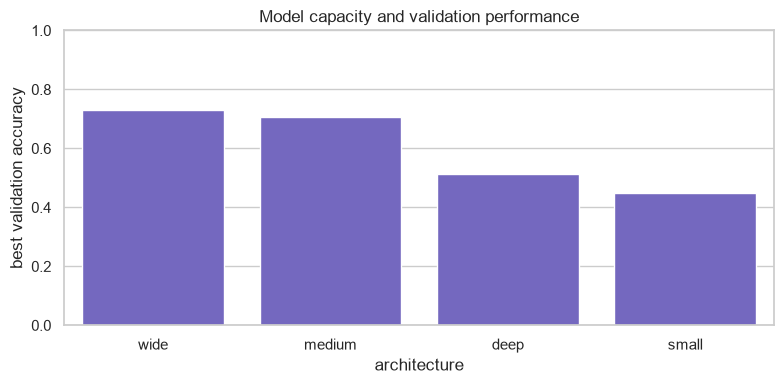

🏃 View run mlp-architecture-small at: http://127.0.0.1:5000/#/experiments/1/runs/fd6daf35aa934f89a188b55d47cdaf4e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-medium at: http://127.0.0.1:5000/#/experiments/1/runs/9437150d0eb74f2490552e1194ba45c9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-wide at: http://127.0.0.1:5000/#/experiments/1/runs/0cfeb61ea9f64006bb618fada776e349
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-deep at: http://127.0.0.1:5000/#/experiments/1/runs/5c0147186b11451ca3380b345e84aafe
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [102]:
architectures = {
    "small": (8,),
    "medium": (32, 16),
    "wide": (128,),
    "deep": (64, 32, 16),
}

capacity_results = []
capacity_histories = {}
capacity_models = {}

for name, hidden_dims in architectures.items():
    capacity_model, capacity_history, best_epoch_capacity = fit_experiment(
        hidden_dims=hidden_dims,
        lr=1e-4,
        epochs=35,
    )
    capacity_histories[name] = capacity_history
    capacity_models[name] = capacity_model
    capacity_results.append({
        "architecture": name,
        "hidden_dims": hidden_dims,
        "parameters": count_parameters(capacity_model),
        "best_epoch": best_epoch_capacity,
        "best_validation_accuracy": max(capacity_history["val_acc"]),
        "final_validation_accuracy": capacity_history["val_acc"][-1],
    })

capacity_table = pd.DataFrame(capacity_results).sort_values(
    "best_validation_accuracy",
    ascending=False,
)
display(capacity_table)

plt.figure(figsize=(8, 4))
sns.barplot(
    data=capacity_table,
    x="architecture",
    y="best_validation_accuracy",
    color="slateblue",
)
plt.ylim(0, 1)
plt.ylabel("best validation accuracy")
plt.title("Model capacity and validation performance")
plt.tight_layout()
plt.show()

for name, hidden_dims in architectures.items():
    architecture_history = capacity_histories[name]
    architecture_series = {
        "train_loss": architecture_history["train_loss"],
        "validation_loss": architecture_history["val_loss"],
        "train_accuracy": architecture_history["train_acc"],
        "validation_accuracy": architecture_history["val_acc"],
    }
    log_mlflow_training_run(
        run_name=f"mlp-architecture-{name}",
        params={
            "framework": "pytorch",
            "architecture": name,
            "hidden_dims": str(hidden_dims),
            "requested_epochs": 35,
            "actual_epochs": len(architecture_history["train_loss"]),
            "best_epoch": next(
                row["best_epoch"]
                for row in capacity_results
                if row["architecture"] == name
            ),
            "learning_rate": 1e-3,
            "random_state": RANDOM_STATE,
        },
        series=architecture_series,
        final_metrics={
            "best_validation_accuracy": max(architecture_history["val_acc"]),
            "best_validation_loss": min(architecture_history["val_loss"]),
        },
        model=capacity_models[name],
        model_type="pytorch",
    )


### results table

| Architecture | Parameters | Train score | Validation score |
|---|---:|---:|---:|
| p → 8 → K | | | |
| p → 32 → 16 → K | | | |
| p → 128 → K | | | |
| p → 64 → 32 → 16 → K | | | |


# Part XIV — Deliberate overfitting

## 29. Build an oversized model

Try something intentionally excessive for the dataset:

```text
p → 256 → 128 → 64 → K
```

Train for more epochs than necessary.

Observe:

$$
training\ loss \downarrow
$$

while validation loss may eventually:

$$
validation\ loss \uparrow
$$


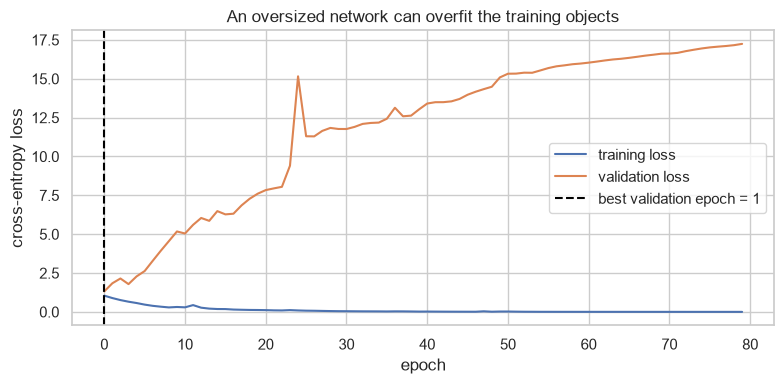

Best validation epoch: 1
Final training loss: 0.0014305239402799814
Final validation loss: 17.244223949236748
🏃 View run mlp-oversized-80-epochs at: http://127.0.0.1:5000/#/experiments/1/runs/b3e539bf67dc498a82c14f639f5fa5ba
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'b3e539bf67dc498a82c14f639f5fa5ba'

In [103]:
oversized_model, oversized_history, oversized_best_epoch = fit_experiment(
    hidden_dims=(256, 128, 64),
    lr=1e-3,
    epochs=80)

plt.figure(figsize=(8, 4))
plt.plot(oversized_history["train_loss"], label="training loss")
plt.plot(oversized_history["val_loss"], label="validation loss")
plt.axvline(
    oversized_best_epoch - 1,
    color="black",
    linestyle="--",
    label=f"best validation epoch = {oversized_best_epoch}",
)
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("An oversized network can overfit the training objects")
plt.legend()
plt.tight_layout()
plt.show()

print("Best validation epoch:", oversized_best_epoch)
print("Final training loss:", oversized_history["train_loss"][-1])
print("Final validation loss:", oversized_history["val_loss"][-1])

log_mlflow_training_run(
    run_name="mlp-oversized-80-epochs",
    params={
        "framework": "pytorch",
        "architecture": "256,128,64",
        "requested_epochs": 80,
        "actual_epochs": len(oversized_history["train_loss"]),
        "best_epoch": oversized_best_epoch,
        "learning_rate": 1e-3,
        "random_state": RANDOM_STATE,
    },
    series={
        "train_loss": oversized_history["train_loss"],
        "validation_loss": oversized_history["val_loss"],
        "train_accuracy": oversized_history["train_acc"],
        "validation_accuracy": oversized_history["val_acc"],
    },
    final_metrics={
        "best_validation_accuracy": max(oversized_history["val_acc"]),
        "best_validation_loss": min(oversized_history["val_loss"]),
    },
    model=oversized_model,
    model_type="pytorch",
)


# Part XV — Regularization

## 30. Weight decay

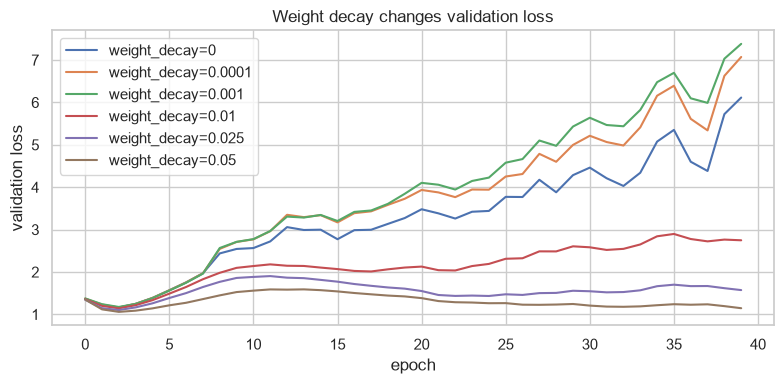

In [104]:
weight_decay_values = [0.0, 1e-4, 1e-3, 0.01, 0.025, 0.05]
weight_decay_results = {}

for weight_decay in weight_decay_values:
    _, history_wd, best_epoch_wd = fit_experiment(
        weight_decay=weight_decay,
        lr=1e-3,
        epochs=40,
    )
    weight_decay_results[weight_decay] = {
        "history": history_wd,
        "best_epoch": best_epoch_wd,
    }

plt.figure(figsize=(8, 4))
for weight_decay, result in weight_decay_results.items():
    plt.plot(
        result["history"]["val_loss"],
        label=f"weight_decay={weight_decay:g}",
    )

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Weight decay changes validation loss")
plt.legend()
plt.tight_layout()
plt.show()

## 31. Dropout

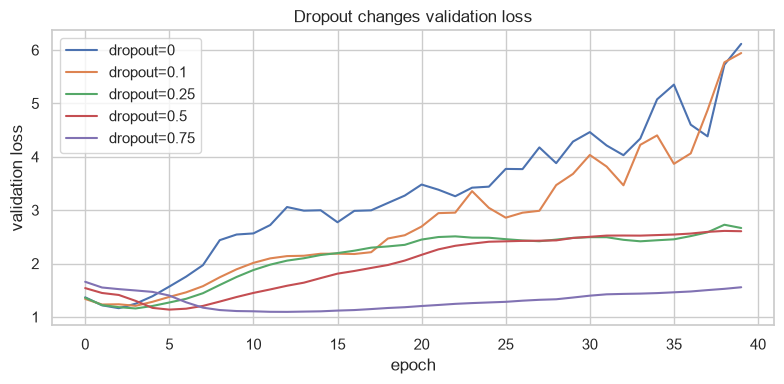

In [105]:
dropout_values = [0.0, 0.1, 0.25, 0.5, 0.75]
dropout_results = {}

for dropout_rate in dropout_values:
    _, history_dropout, best_epoch_dropout = fit_experiment(
        dropout=dropout_rate,
        lr=1e-3,
        epochs=40,
    )
    dropout_results[dropout_rate] = {
        "history": history_dropout,
        "best_epoch": best_epoch_dropout,
    }

plt.figure(figsize=(8, 4))
for dropout_rate, result in dropout_results.items():
    plt.plot(
        result["history"]["val_loss"],
        label=f"dropout={dropout_rate:g}",
    )

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Dropout changes validation loss")
plt.legend()
plt.tight_layout()
plt.show()

## 32. Early stopping

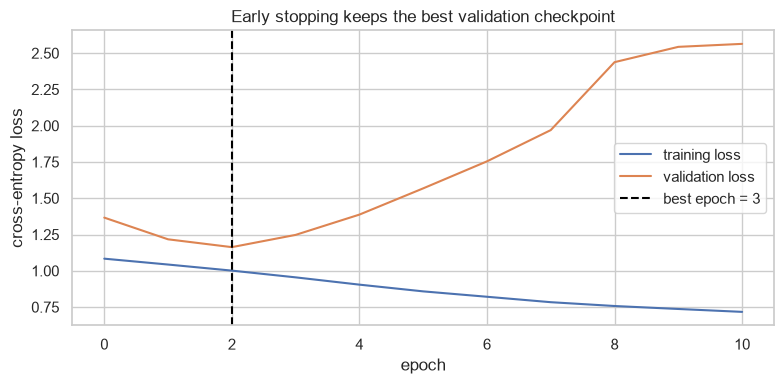

Epochs actually trained: 11
Best validation epoch: 3
🏃 View run mlp-early-stopping at: http://127.0.0.1:5000/#/experiments/1/runs/48d083b93a144abc8674a4402f932146
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'48d083b93a144abc8674a4402f932146'

In [106]:
early_stop_model, early_stop_history, early_stop_best_epoch = fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    epochs=100,
    patience=8,
)

plt.figure(figsize=(8, 4))
plt.plot(early_stop_history["train_loss"], label="training loss")
plt.plot(early_stop_history["val_loss"], label="validation loss")
plt.axvline(
    early_stop_best_epoch - 1,
    color="black",
    linestyle="--",
    label=f"best epoch = {early_stop_best_epoch}",
)
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Early stopping keeps the best validation checkpoint")
plt.legend()
plt.tight_layout()
plt.show()

print("Epochs actually trained:", len(early_stop_history["train_loss"]))
print("Best validation epoch:", early_stop_best_epoch)

log_mlflow_training_run(
    run_name="mlp-early-stopping",
    params={
        "framework": "pytorch",
        "architecture": "32,16",
        "requested_epochs": 100,
        "actual_epochs": len(early_stop_history["train_loss"]),
        "best_epoch": early_stop_best_epoch,
        "patience": 8,
        "learning_rate": 1e-3,
        "random_state": RANDOM_STATE,
    },
    series={
        "train_loss": early_stop_history["train_loss"],
        "validation_loss": early_stop_history["val_loss"],
        "train_accuracy": early_stop_history["train_acc"],
        "validation_accuracy": early_stop_history["val_acc"],
    },
    final_metrics={
        "best_validation_accuracy": max(early_stop_history["val_acc"]),
        "best_validation_loss": min(early_stop_history["val_loss"]),
    },
    model=early_stop_model,
    model_type="pytorch",
)


## 33. Compare regularization strategies

| Model | Dropout | Weight decay | Early stopping | Validation score |
|---|---:|---:|---:|---:|
| Baseline | | | | |
| + Weight decay | | | | |
| + Dropout | | | | |
| + Early stopping | | | | |


,strategy,best_epoch,best_val_loss,best_val_accuracy
0,baseline,3,1.162903,0.794872
1,weight decay 1e-4,3,1.160479,0.794872
2,dropout 0.25,4,1.158105,0.807692
3,early stopping,3,1.162903,0.730769


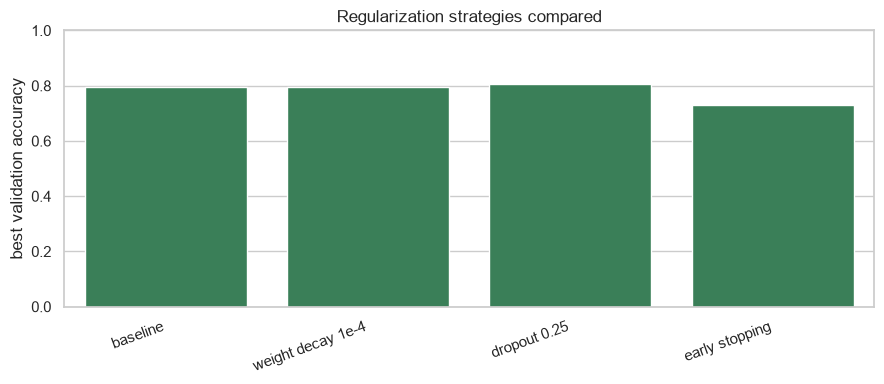

In [107]:
def best_validation_summary(history):
    best_index = int(np.argmin(history["val_loss"]))
    return {
        "best_epoch": best_index + 1,
        "best_val_loss": history["val_loss"][best_index],
        "best_val_accuracy": max(history["val_acc"]),
    }

regularization_summary = pd.DataFrame([
    {
        "strategy": "baseline",
        **best_validation_summary(learning_rate_results[1e-3]["history"]),
    },
    {
        "strategy": "weight decay 1e-4",
        **best_validation_summary(weight_decay_results[1e-4]["history"]),
    },
    {
        "strategy": "dropout 0.25",
        **best_validation_summary(dropout_results[0.25]["history"]),
    },
    {
        "strategy": "early stopping",
        **best_validation_summary(early_stop_history),
    },
])

display(regularization_summary)

plt.figure(figsize=(9, 4))
sns.barplot(
    data=regularization_summary,
    x="strategy",
    y="best_val_accuracy",
    color="seagreen",
)
plt.ylim(0, 1)
plt.ylabel("best validation accuracy")
plt.xlabel("")
plt.title("Regularization strategies compared")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Part XVI — Final test evaluation

In [108]:
best_model = early_stop_model

test_loss, test_acc = evaluate(
    best_model,
    test_loader,
    criterion,
    DEVICE,
)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 1.0319296811756336
Test accuracy: 0.5


## 34. Detailed classification metrics

              precision    recall  f1-score   support

          m0      0.424     0.962     0.588        26
          m1      0.692     0.429     0.529        21
          m2      1.000     0.138     0.242        29

    accuracy                          0.500        76
   macro avg      0.705     0.509     0.453        76
weighted avg      0.718     0.500     0.440        76



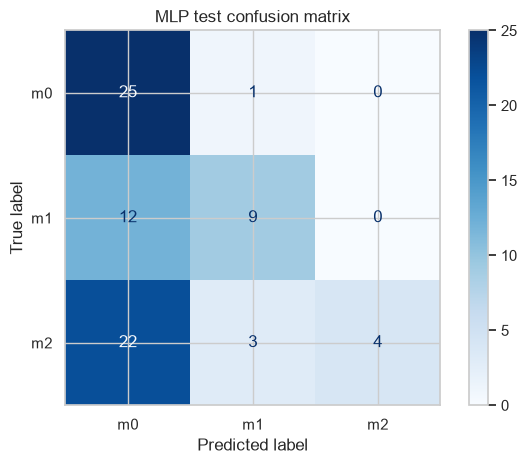

In [109]:
best_model.eval()
all_logits = []
all_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        all_logits.append(best_model(X_batch.to(DEVICE)).cpu())
        all_targets.append(y_batch.cpu())

test_logits = torch.cat(all_logits).numpy()
y_true = torch.cat(all_targets).numpy()
y_pred = test_logits.argmax(axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=3,
))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
)
plt.title("MLP test confusion matrix")
plt.tight_layout()
plt.show()

# Part XVII — Compare with classical models

## 35. Logistic Regression baseline

A neural network is not automatically better than a simpler model.


In [110]:
logreg = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE,
)
logreg.fit(X_train_scaled, y_train)
pred_logreg = logreg.predict(X_test_scaled)

print("Logistic regression balanced accuracy:", balanced_accuracy_score(y_test, pred_logreg))
print("Logistic regression macro F1:", f1_score(y_test, pred_logreg, average="macro"))

Logistic regression balanced accuracy: 0.7858405961854237
Logistic regression macro F1: 0.7889484443156759


## 36. XGBoost baseline and an Optuna hyperparameter search

XGBoost builds trees sequentially, with each new tree correcting errors made by earlier trees. Instead of evaluating every point in a large Cartesian grid, Optuna proposes promising configurations based on previous trials.

The search explores:

- `n_estimators`: number of boosting trees;
- `max_depth`: maximum depth of each tree;
- `learning_rate`: contribution of each new tree;
- `min_child_weight`: minimum amount of data needed for a child split;
- `subsample` and `colsample_bytree`: row and feature subsampling;
- `gamma` and `reg_lambda`: additional regularization.

Each trial is evaluated with three stratified group-aware folds using macro F1. The held-out validation and test sets are not used by Optuna. Twenty trials provide a compact teaching-time search budget; students can increase this value for a more exhaustive analysis.

Completed Optuna trials: 20
Best XGBoost parameters: {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.026855503485582764, 'min_child_weight': 1, 'subsample': 0.8999999999999999, 'colsample_bytree': 0.7999999999999999, 'gamma': 0.3792048504426779, 'reg_lambda': 0.03652791692410506}
Best group-CV macro F1: 0.800


,number,value
19,19,0.799531
10,10,0.789102
9,9,0.786982
14,14,0.784117
17,17,0.782029
16,16,0.780823
5,5,0.780319
6,6,0.777359
13,13,0.773497
11,11,0.771086


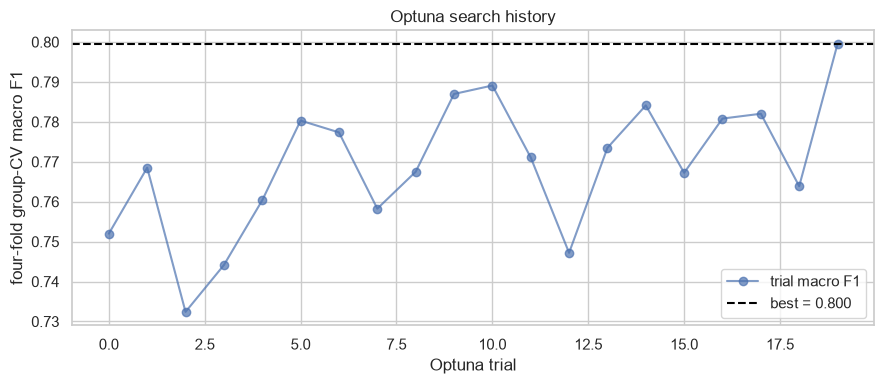

Selected XGBoost validation balanced accuracy: 0.7647266313932981
Selected XGBoost validation macro F1: 0.7652073335794265
Selected XGBoost test balanced accuracy: 0.601490463559429
Selected XGBoost test macro F1: 0.606891589382795
🏃 View run xgboost-optuna-best at: http://127.0.0.1:5000/#/experiments/1/runs/32d6454e926c4d4f81243ce49632f379
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'32d6454e926c4d4f81243ce49632f379'

In [111]:
import tempfile
from pathlib import Path

xgb_train_y = y_train.map(class_to_index).to_numpy(dtype=np.int64)
xgb_val_y = y_val.map(class_to_index).to_numpy(dtype=np.int64)

xgb_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE + 2,
)
xgb_cv_splits = list(
    xgb_cv.split(
        X_train_imputed,
        xgb_train_y,
        groups=groups_train.to_numpy(),
    )
)

optuna.logging.set_verbosity(optuna.logging.WARNING)

from joblib import Parallel, delayed

# XGBoost runs in loky worker processes: loading it in the same process as
# PyTorch can crash/hang on macOS (two OpenMP runtimes).
def xgb_fold_f1(params, X_fit, y_fit, X_eval, y_eval):
    from xgboost import XGBClassifier
    from sklearn.metrics import f1_score
    model = XGBClassifier(
        objective="multi:softprob", num_class=n_classes, eval_metric="mlogloss",
        tree_method="hist", random_state=RANDOM_STATE, n_jobs=1, verbosity=0, **params,
    )
    model.fit(X_fit, y_fit)
    return f1_score(y_eval, model.predict(X_eval).astype(int), average="macro")


def xgb_fit_and_predict(params, X_fit, y_fit, X_list, model_path):
    from xgboost import XGBClassifier
    model = XGBClassifier(
        objective="multi:softprob", num_class=n_classes, eval_metric="mlogloss",
        tree_method="hist", random_state=RANDOM_STATE, n_jobs=1, verbosity=0, **params,
    )
    model.fit(X_fit, y_fit)
    model.save_model(model_path)
    return [model.predict(X_).astype(int) for X_ in X_list]


def xgb_objective(trial):
    trial_params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 250, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0, step=0.1),
        "gamma": trial.suggest_float("gamma", 0.0, 0.5),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    fold_scores = Parallel(n_jobs=3, backend="loky")(
        delayed(xgb_fold_f1)(
            trial_params,
            X_train_imputed[tr], xgb_train_y[tr],
            X_train_imputed[va], xgb_train_y[va],
        )
        for tr, va in xgb_cv_splits
    )
    return float(np.mean(fold_scores))


xgb_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
xgb_study.optimize(
    xgb_objective,
    n_trials=20,
    show_progress_bar=False,
)

print("Completed Optuna trials:", len(xgb_study.trials))
print("Best XGBoost parameters:", xgb_study.best_params)
print(f"Best group-CV macro F1: {xgb_study.best_value:.3f}")

optuna_results = (
    xgb_study.trials_dataframe()
    .query("state == 'COMPLETE'")
    .sort_values("value", ascending=False)
    [["number", "value"]]
    .head(10)
)
display(optuna_results)

all_trial_values = [
    trial.value
    for trial in xgb_study.trials
    if trial.value is not None
]
plt.figure(figsize=(9, 4))
plt.plot(all_trial_values, marker="o", alpha=0.7, label="trial macro F1")
plt.axhline(
    xgb_study.best_value,
    color="black",
    linestyle="--",
    label=f"best = {xgb_study.best_value:.3f}",
)
plt.xlabel("Optuna trial")
plt.ylabel("four-fold group-CV macro F1")
plt.title("Optuna search history")
plt.legend()
plt.tight_layout()
plt.show()

xgb_model_path = str(Path(tempfile.gettempdir()) / "xgboost_model.json")
pred_xgb_val_codes, pred_xgb_codes = Parallel(n_jobs=2, backend="loky")(
    [delayed(xgb_fit_and_predict)(
        xgb_study.best_params, X_train_imputed, xgb_train_y,
        [X_val_imputed, X_test_imputed], xgb_model_path,
    )]
)[0]

pred_xgb_val = np.asarray(class_names)[pred_xgb_val_codes]

print(
    "Selected XGBoost validation balanced accuracy:",
    balanced_accuracy_score(y_val, pred_xgb_val),
)
print(
    "Selected XGBoost validation macro F1:",
    f1_score(y_val, pred_xgb_val, average="macro"),
)

pred_xgb = np.asarray(class_names)[pred_xgb_codes]

print("Selected XGBoost test balanced accuracy:", balanced_accuracy_score(y_test, pred_xgb))
print("Selected XGBoost test macro F1:", f1_score(y_test, pred_xgb, average="macro"))

xgb_validation_metrics = {
    "validation_balanced_accuracy": balanced_accuracy_score(y_val, pred_xgb_val),
    "validation_macro_f1": f1_score(y_val, pred_xgb_val, average="macro"),
    "test_balanced_accuracy": balanced_accuracy_score(y_test, pred_xgb),
    "test_macro_f1": f1_score(y_test, pred_xgb, average="macro"),
    "best_group_cv_macro_f1": xgb_study.best_value,
}
log_mlflow_training_run(
    run_name="xgboost-optuna-best",
    params={
        "framework": "xgboost",
        "search_method": "Optuna TPE",
        "search_trials": len(xgb_study.trials),
        "random_state": RANDOM_STATE,
        **xgb_study.best_params,
    },
    final_metrics=xgb_validation_metrics,
    model=xgb_model_path,
    model_type="xgboost",
)


## 37. Final comparison

| Model | Balanced accuracy | Macro F1 | Notes |
|---|---:|---:|---|
| Logistic Regression | | | linear baseline |
| XGBoost | | | tuned tree-boosting model |
| MLP | | | neural-network model |

,model,balanced_accuracy,macro_f1
0,Logistic Regression,0.785841,0.788948
1,XGBoost,0.601490,0.606892
2,MLP,0.509347,0.453357


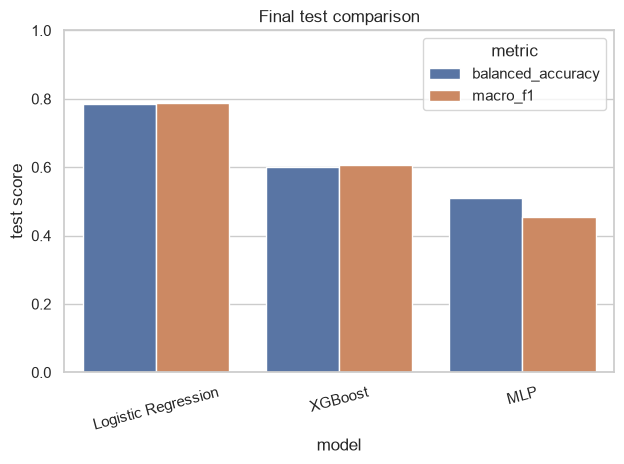

In [112]:
pred_mlp_labels = np.asarray(class_names)[y_pred]

comparison = pd.DataFrame([
    {
        "model": "MLP",
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_mlp_labels),
        "macro_f1": f1_score(y_test, pred_mlp_labels, average="macro"),
    },
    {
        "model": "Logistic Regression",
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_logreg),
        "macro_f1": f1_score(y_test, pred_logreg, average="macro"),
    },
    {
        "model": "XGBoost",
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_xgb),
        "macro_f1": f1_score(y_test, pred_xgb, average="macro"),
    },
]).sort_values("macro_f1", ascending=False).reset_index(drop=True)

display(comparison)

comparison_plot = comparison.melt(
    id_vars="model",
    value_vars=["balanced_accuracy", "macro_f1"],
    var_name="metric",
    value_name="score",
)
sns.barplot(data=comparison_plot, x="model", y="score", hue="metric")
plt.ylim(0, 1)
plt.ylabel("test score")
plt.title("Final test comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Discussion

- Did the MLP outperform the simpler models?
- Was the performance gain worth the added complexity?
- Which model is easier to interpret?
- Which model would you deploy for this biological problem?


# Part XVIII — TensorFlow / Keras comparison

## 38. Same architecture in Keras

We keep PyTorch as the main teaching framework, then show that the same layer and loss ideas exist in Keras.

On native Windows, TensorFlow 2.11 and later does not use CUDA GPU acceleration. A warning about unavailable TensorFlow GPU support is expected on native Windows; it is not the cause of the dtype error. GPU TensorFlow requires WSL2 or an alternative such as DirectML.

In [113]:
from joblib import Parallel, delayed

# TensorFlow runs in a separate worker process: importing it next to PyTorch in the
# notebook kernel can hang on macOS (two OpenMP runtimes in one process).
def build_keras_model(input_dim, n_classes):
    from tensorflow import keras
    return keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(n_classes),
    ])


def keras_summary(input_dim, n_classes):
    lines = []
    build_keras_model(input_dim, n_classes).summary(print_fn=lines.append)
    return "\n".join(lines)


print(Parallel(n_jobs=2, backend="loky")([delayed(keras_summary)(input_dim, n_classes)])[0])


Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 2,179 (8.51 KB)
 Trainable params: 2,179 (8.51 KB)
 Non-trainable params: 0 (0.00 B)



## 39. Compile and train

In [114]:
# SparseCategoricalCrossentropy expects integer class codes,
# not the original string labels m0, m1, and m2.
import tempfile
from pathlib import Path

y_train_keras = y_train.map(class_to_index).to_numpy(dtype=np.int64)
y_val_keras = y_val.map(class_to_index).to_numpy(dtype=np.int64)
X_train_keras = np.asarray(X_train_scaled, dtype=np.float32)
X_val_keras = np.asarray(X_val_scaled, dtype=np.float32)


def train_keras(X_tr, y_tr, X_va, y_va, input_dim, n_classes, model_path):
    from tensorflow import keras
    keras.utils.set_random_seed(RANDOM_STATE)
    model = build_keras_model(input_dim, n_classes)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    fit_history = model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=50,
        batch_size=32,
        verbose=0,
    )
    model.save(model_path)
    return fit_history.history


keras_model_path = str(Path(tempfile.gettempdir()) / "keras_model.keras")
history_keras = Parallel(n_jobs=2, backend="loky")(
    [delayed(train_keras)(
        X_train_keras, y_train_keras, X_val_keras, y_val_keras,
        input_dim, n_classes, keras_model_path,
    )]
)[0]

keras_series = {
    "train_loss": history_keras["loss"],
    "validation_loss": history_keras["val_loss"],
    "train_accuracy": history_keras["accuracy"],
    "validation_accuracy": history_keras["val_accuracy"],
}
print(f"Keras final validation accuracy: {keras_series['validation_accuracy'][-1]:.3f}")
log_mlflow_training_run(
    run_name="keras-baseline",
    params={
        "framework": "keras",
        "architecture": "32,16",
        "input_dim": input_dim,
        "n_classes": n_classes,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "epochs": len(keras_series["train_loss"]),
        "batch_size": 32,
        "random_state": RANDOM_STATE,
    },
    series=keras_series,
    final_metrics={
        "final_validation_accuracy": keras_series["validation_accuracy"][-1],
        "best_validation_accuracy": max(keras_series["validation_accuracy"]),
        "best_validation_loss": min(keras_series["validation_loss"]),
    },
    model=keras_model_path,
    model_type="keras",
)


Keras final validation accuracy: 0.808
🏃 View run keras-baseline at: http://127.0.0.1:5000/#/experiments/1/runs/5d68884fb9174a3f9cca407a85b9f62a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'5d68884fb9174a3f9cca407a85b9f62a'

## 40. PyTorch vs Keras

| Concept | PyTorch | Keras |
|---|---|---|
| Dense layer | `nn.Linear` | `Dense` |
| Activation | `nn.ReLU()` | `activation="relu"` |
| Loss | explicit object | `compile(loss=...)` |
| Optimizer | explicit object | `compile(optimizer=...)` |
| Training loop | explicit by default | usually hidden in `fit()` |
| Gradients | `loss.backward()` | automatic inside `fit()` |


## Part XIX — Hometask: VGG3D embeddings and cell-type classification

Use the alternative VGG3D representation of the same microscopy experiment:

```text
week6/large_object_vgg3d_embeddings_processed.csv
```

The target is `cell_type` with classes `m0`, `m1`, and `m2`. Do not use `sample_group` as a predictive feature; use it only to create leakage-safe partitions.

## Instructions

1. Inspect the table and complete a short preparation checklist: shape, data types, class balance, missingness, duplicate rows, feature ranges, and the meaning of `sample_group`.
2. Perform exploratory analysis with feature distributions and a PCA plus t-SNE or UMAP plot coloured by `cell_type`. Treat these projections as exploratory, not as test-set evaluation.
3. Create group-aware train, validation, and test partitions. Fit imputation and scaling on the training partition only, and verify that no `sample_group` occurs in more than one partition.
4. Train a multinomial logistic-regression baseline and a PyTorch MLP. Report learning curves, balanced accuracy, macro-F1, and a confusion matrix.
5. Run controlled MLP experiments: at least three learning rates, two network capacities, and two regularisation settings involving weight decay, dropout, or early stopping. Keep the split and random seed fixed.
6. Select the final model using validation data, evaluate it once on the untouched test set, and explain the errors biologically and statistically.

## Questions for the report

1. What does the VGG3D embedding table contain, and what data-preparation problems did you find?
2. Does the embedding space show separation between `m0`, `m1`, and `m2`? Is the separation also visible across sample groups?
3. How much does the MLP improve over logistic regression, and what evidence supports the comparison?
4. Which learning rate, capacity, and regularisation setting worked best? Did the MLP overfit?
5. Which cell types are confused most often, and do the errors concentrate in particular sample groups?
6. What biological or technical information is missing that could help explain the remaining errors?

## Deliverables

- completed notebook;
- preparation and leakage checks;
- PCA and t-SNE/UMAP visualisations;
- model comparison and learning-curve figures;
- final confusion matrix and six-question report.


### H.0 Setup and data inspection (VGG3D embeddings)

Same task as in the main practical, different representation: each object is now described by a 128-dimensional VGG3D embedding instead of handcrafted morphology. `sample_group` identifies the biological sample an object came from and is **never** a predictive feature; it is used only to build leakage-safe splits.

In [115]:
import copy
import random
import seaborn as sns
from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, silhouette_score
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, TensorDataset

HW_SEED = 141026
def set_seed(seed=HW_SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

hw = pd.read_csv("large_object_vgg3d_embeddings_processed.csv")
HW_TARGET, HW_GROUP = "cell_type", "sample_group"
hw_feats = [c for c in hw.columns if c not in (HW_TARGET, HW_GROUP)]
print("shape:", hw.shape, "| features:", len(hw_feats), "| non-numeric feature columns:",
      [c for c in hw_feats if not pd.api.types.is_numeric_dtype(hw[c])])
print("missing cells:", int(hw[hw_feats].isna().sum().sum()), "| rows with NaN:", int(hw[hw_feats].isna().any(axis=1).sum()))
print("duplicated rows:", int(hw.duplicated().sum()), "| inf values:", int(np.isinf(hw[hw_feats].to_numpy()).sum()))
print("zero-variance features:", int((hw[hw_feats].std() == 0).sum()), "| negative values:", int((hw[hw_feats] < 0).sum().sum()))
print("feature range: min %.3f, max %.3f" % (hw[hw_feats].to_numpy().min(), hw[hw_feats].to_numpy().max()))
print("objects:", len(hw), "| sample groups:", hw[HW_GROUP].nunique(), "| classes per group:",
      hw.groupby(HW_GROUP)[HW_TARGET].nunique().value_counts().to_dict())
print("group size: min %d, median %d, max %d" % tuple(hw.groupby(HW_GROUP).size().agg(["min", "median", "max"])))

shape: (381, 130) | features: 128 | non-numeric feature columns: []
missing cells: 0 | rows with NaN: 0
duplicated rows: 0 | inf values: 0
zero-variance features: 37 | negative values: 0
feature range: min 0.000, max 44.923
objects: 381 | sample groups: 85 | classes per group: {1: 85}
group size: min 1, median 3, max 22


**Checklist outcome.** No missing values, no duplicated rows, no infinities; all features numeric and non-negative (activations after a ReLU, hence many exact zeros). Some features are constant (zero variance) and carry no information; they are dropped using the training set only. Every `sample_group` contains a single cell type, so the group is a perfect proxy for the label: a random split would put objects from the same sample in train and test and the model could simply recognise the sample. All splits below are therefore **group-aware**.

### H.1 Exploratory analysis

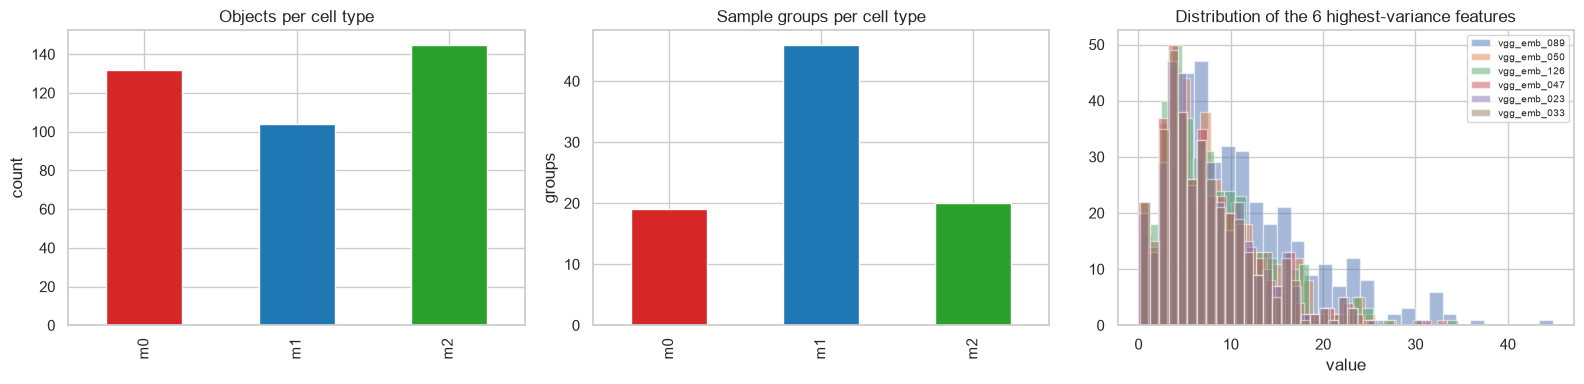

Sparsity: fraction of exact zeros = 0.58
Missingness per feature (max): 0% | per row (max): 0%


In [116]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hw[HW_TARGET].value_counts().sort_index().plot.bar(ax=axes[0], color=["tab:red", "tab:blue", "tab:green"])
axes[0].set(title="Objects per cell type", xlabel="", ylabel="count")
hw.groupby(HW_TARGET)[HW_GROUP].nunique().plot.bar(ax=axes[1], color=["tab:red", "tab:blue", "tab:green"])
axes[1].set(title="Sample groups per cell type", xlabel="", ylabel="groups")
hw_feats_sel = list(hw[hw_feats].var().sort_values(ascending=False).index[:6])
for f in hw_feats_sel:
    axes[2].hist(hw[f], bins=30, alpha=0.5, label=f)
axes[2].set(title="Distribution of the 6 highest-variance features", xlabel="value")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

print("Sparsity: fraction of exact zeros = %.2f" % (hw[hw_feats] == 0).to_numpy().mean())
print("Missingness per feature (max): %.0f%% | per row (max): %.0f%%" % (100 * hw[hw_feats].isna().mean().max(), 100 * hw[hw_feats].isna().mean(axis=1).max()))

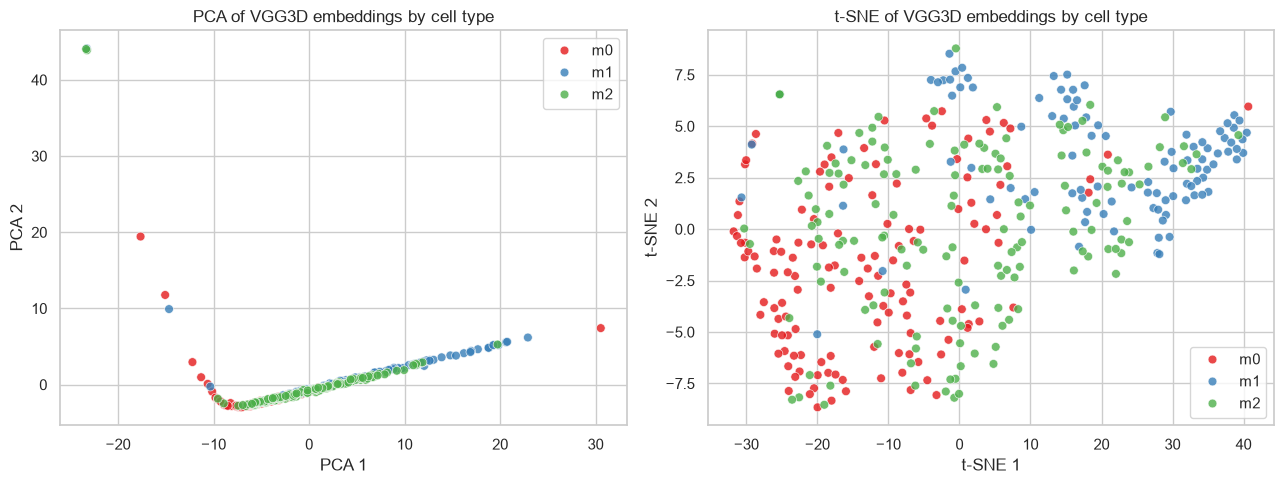

Silhouette of cell_type: scaled embedding 0.041 | PCA-2 0.047 | t-SNE-2 0.067


In [117]:
hw_eda_scaled = StandardScaler().fit_transform(hw[hw_feats])   # unsupervised, exploration only
hw_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=HW_SEED).fit_transform(hw_eda_scaled)
hw_pca2 = PCA(n_components=2, random_state=HW_SEED).fit_transform(hw_eda_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, emb, name in zip(axes, [hw_pca2, hw_tsne], ["PCA", "t-SNE"]):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=hw[HW_TARGET].to_numpy(), hue_order=["m0", "m1", "m2"],
                    palette="Set1", s=40, alpha=0.8, ax=ax)
    ax.set_title(f"{name} of VGG3D embeddings by cell type"); ax.set_xlabel(f"{name} 1"); ax.set_ylabel(f"{name} 2")
plt.tight_layout()
plt.show()
print("Silhouette of cell_type: scaled embedding %.3f | PCA-2 %.3f | t-SNE-2 %.3f" % (
    silhouette_score(hw_eda_scaled, hw[HW_TARGET]), silhouette_score(hw_pca2, hw[HW_TARGET]), silhouette_score(hw_tsne, hw[HW_TARGET])))
# Exploratory only: these plots use all objects, none of this feeds into model selection or test evaluation.

### H.2 Leakage-safe splitting and preprocessing

1. **Test split (20%)**: `StratifiedGroupKFold(5)`, choose the fold whose size and class proportions are closest to 20% / overall; the test set is not touched until the final evaluation.
2. **Validation split (25% of the remainder)**: again group-aware, taken from the training portion only.
3. **Preprocessing**: zero-variance filter, median imputer (defensive; there is no missingness) and `StandardScaler` are **fitted on the training rows only** and then applied to validation and test.

In [118]:
def split_quality(test_indices, y_values, target_fraction):
    overall = y_values.value_counts(normalize=True).sort_index()
    part = y_values.iloc[test_indices].value_counts(normalize=True).reindex(overall.index).fillna(0)
    return abs(len(test_indices) / len(y_values) - target_fraction) + np.abs(part - overall).sum()

def group_split(X_, y_, g_, n_splits, fraction, seed):
    splits = list(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed).split(X_, y_, groups=g_))
    best = min(range(len(splits)), key=lambda i: split_quality(splits[i][1], y_, fraction))
    return splits[best]

hw_X, hw_y, hw_g = hw[hw_feats], hw[HW_TARGET], hw[HW_GROUP]
tr_full, te = group_split(hw_X, hw_y, hw_g, 5, 0.20, HW_SEED)
Xf, yf, gf = hw_X.iloc[tr_full], hw_y.iloc[tr_full], hw_g.iloc[tr_full]
tr, va = group_split(Xf, yf, gf, 4, 0.25, HW_SEED + 1)

hw_Xtr, hw_ytr, hw_gtr = Xf.iloc[tr], yf.iloc[tr], gf.iloc[tr]
hw_Xva, hw_yva, hw_gva = Xf.iloc[va], yf.iloc[va], gf.iloc[va]
hw_Xte, hw_yte, hw_gte = hw_X.iloc[te], hw_y.iloc[te], hw_g.iloc[te]

assert not set(hw_gtr) & set(hw_gva) and not set(hw_gtr) & set(hw_gte) and not set(hw_gva) & set(hw_gte)
summary = pd.DataFrame({
    "objects": [len(hw_ytr), len(hw_yva), len(hw_yte)],
    "groups": [hw_gtr.nunique(), hw_gva.nunique(), hw_gte.nunique()],
    "m0": [(s == "m0").sum() for s in (hw_ytr, hw_yva, hw_yte)],
    "m1": [(s == "m1").sum() for s in (hw_ytr, hw_yva, hw_yte)],
    "m2": [(s == "m2").sum() for s in (hw_ytr, hw_yva, hw_yte)]}, index=["train", "validation", "test"])
display(summary)
print("No group is shared between train, validation and test.")

keep = hw_Xtr.columns[hw_Xtr.std() > 0]            # zero-variance filter learned on train only
hw_imputer = SimpleImputer(strategy="median").fit(hw_Xtr[keep])
hw_scaler = StandardScaler().fit(hw_imputer.transform(hw_Xtr[keep]))
prep = lambda df: hw_scaler.transform(hw_imputer.transform(df[keep])).astype(np.float32)
Xtr_s, Xva_s, Xte_s = prep(hw_Xtr), prep(hw_Xva), prep(hw_Xte)
hw_classes = ["m0", "m1", "m2"]
c2i = {c: i for i, c in enumerate(hw_classes)}
ytr_i, yva_i, yte_i = (s.map(c2i).to_numpy() for s in (hw_ytr, hw_yva, hw_yte))
print("features kept:", len(keep), "of", len(hw_feats), "| train mean/std check:", Xtr_s.mean().round(3), Xtr_s.std().round(3))

,objects,groups,m0,m1,m2
train,230,51,80,62,88
validation,75,17,26,21,28
test,76,17,26,21,29


No group is shared between train, validation and test.
features kept: 91 of 128 | train mean/std check: 0.0 1.0


### H.3 Baselines: multinomial logistic regression and a first MLP

In [119]:
def score(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

lr_rows = []
for C_ in [0.001, 0.01, 0.1, 1.0]:
    m = LogisticRegression(C=C_, max_iter=5000, class_weight="balanced").fit(Xtr_s, ytr_i)
    lr_rows.append({"C": C_, **{f"val_{k}": v for k, v in score(yva_i, m.predict(Xva_s)).items()},
                    "train_balanced_accuracy": balanced_accuracy_score(ytr_i, m.predict(Xtr_s))})
lr_table = pd.DataFrame(lr_rows)
display(lr_table.round(3))
best_C = float(lr_table.loc[lr_table["val_macro_f1"].idxmax(), "C"])
logreg = LogisticRegression(C=best_C, max_iter=5000, class_weight="balanced").fit(Xtr_s, ytr_i)
print("Selected C (validation macro-F1):", best_C)

,C,val_accuracy,val_balanced_accuracy,val_macro_f1,train_balanced_accuracy
0,0.001,0.547,0.565,0.538,0.644
1,0.010,0.627,0.644,0.628,0.665
2,0.100,0.640,0.652,0.646,0.694
3,1.000,0.653,0.668,0.668,0.751


Selected C (validation macro-F1): 1.0


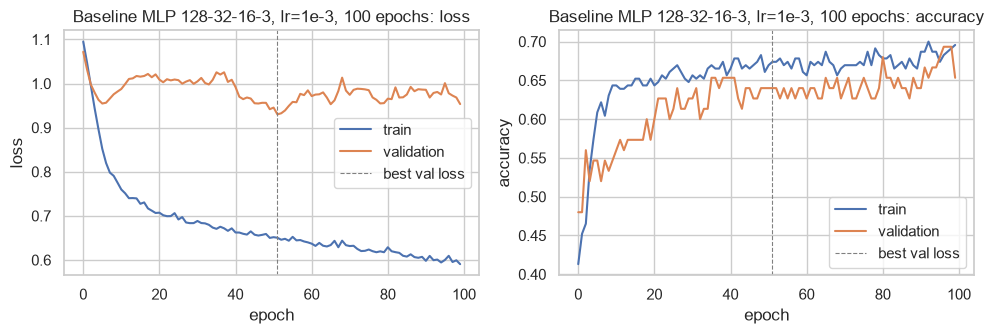

Baseline MLP: {'train_acc': 0.696, 'val_accuracy': 0.653, 'val_balanced_accuracy': 0.669, 'val_macro_f1': 0.654} | best val-loss epoch: 51


In [120]:
class HwMLP(nn.Module):
    def __init__(self, input_dim, hidden=(32, 16), n_classes=3, dropout=0.0):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.network = nn.Sequential(*layers)
    def forward(self, x): return self.network(x)

def make_loader(X_, y_, shuffle, seed=HW_SEED):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(TensorDataset(torch.tensor(X_), torch.tensor(y_, dtype=torch.long)),
                      batch_size=32, shuffle=shuffle, generator=g if shuffle else None)

hw_train_loader = make_loader(Xtr_s, ytr_i, True)
hw_val_loader = make_loader(Xva_s, yva_i, False)

class_weights = torch.tensor(len(ytr_i) / (3 * np.bincount(ytr_i)), dtype=torch.float32)
hw_criterion = nn.CrossEntropyLoss(weight=class_weights)   # balances m0/m1/m2

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    loss_sum = correct = n = 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            logits = model(xb)
            loss = hw_criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * len(xb); correct += (logits.argmax(1) == yb).sum().item(); n += len(xb)
    return loss_sum / n, correct / n

def fit_mlp(hidden=(32, 16), lr=1e-3, weight_decay=0.0, dropout=0.0, epochs=100, patience=None, seed=HW_SEED):
    """Train with fixed seed. patience=None: run all epochs and keep the last model.
    patience=k: early stopping on validation loss, restoring the best weights."""
    set_seed(seed)
    model = HwMLP(Xtr_s.shape[1], hidden, 3, dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = make_loader(Xtr_s, ytr_i, True, seed)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, best_epoch, wait = np.inf, None, 0, 0
    for epoch in range(epochs):
        tl, ta = run_epoch(model, loader, opt)
        vl, va_ = run_epoch(model, hw_val_loader)
        for k, v in zip(hist, (tl, vl, ta, va_)): hist[k].append(v)
        if vl < best_loss - 1e-4:
            best_loss, best_state, best_epoch, wait = vl, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if patience is not None and wait >= patience: break
    hist["best_epoch"] = best_epoch
    if patience is not None: model.load_state_dict(best_state)
    return model, hist

def predict(model, X_):
    model.eval()
    with torch.no_grad(): return model(torch.tensor(X_)).argmax(1).numpy()

def val_summary(model, hist):
    return {"train_acc": hist["train_acc"][-1] if hist else np.nan,
            **{f"val_{k}": v for k, v in score(yva_i, predict(model, Xva_s)).items()}}

def plot_curves(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, key, lab in zip(axes, ["loss", "acc"], ["loss", "accuracy"]):
        ax.plot(hist[f"train_{key}"], label="train"); ax.plot(hist[f"val_{key}"], label="validation")
        ax.axvline(hist["best_epoch"], color="grey", ls="--", lw=0.8, label="best val loss")
        ax.set(xlabel="epoch", ylabel=lab, title=f"{title}: {lab}")
        ax.legend()
    plt.tight_layout(); plt.show()

mlp0, hist0 = fit_mlp()
plot_curves(hist0, "Baseline MLP 128-32-16-3, lr=1e-3, 100 epochs")
print("Baseline MLP:", {k: round(v, 3) for k, v in val_summary(mlp0, hist0).items()}, "| best val-loss epoch:", hist0["best_epoch"])

### H.4 Experiments (fixed seed, selection on validation only)

Every configuration uses the same seed, the same splits and the same preprocessing, so differences come from the setting being changed. With roughly 70 validation objects from a handful of samples, small differences are noise, so we prefer simple settings unless the gain is clear.

,lr,final_train_loss,final_val_loss,min_val_loss,best_epoch,train_acc,val_accuracy,val_balanced_accuracy,val_macro_f1
0,0.000,1.062,1.070,1.070,99,0.465,0.480,0.484,0.393
1,0.000,0.759,0.971,0.951,52,0.639,0.560,0.573,0.557
2,0.001,0.591,0.953,0.930,51,0.696,0.653,0.669,0.654
3,0.010,0.461,1.646,0.958,25,0.774,0.640,0.647,0.656
4,0.100,0.814,0.949,0.875,46,0.557,0.533,0.570,0.454


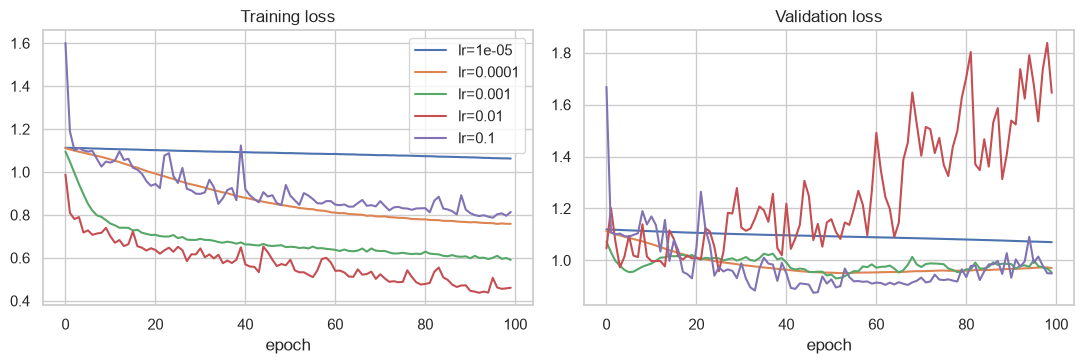

Learning rate with the best validation macro-F1 (ties: lower final validation loss): 0.01


In [121]:
# (a) learning rate
lr_results, lr_hists = [], {}
for lr in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    m, h = fit_mlp(lr=lr)
    lr_hists[lr] = h
    lr_results.append({"lr": lr, "final_train_loss": h["train_loss"][-1], "final_val_loss": h["val_loss"][-1],
                       "min_val_loss": min(h["val_loss"]), "best_epoch": h["best_epoch"], **val_summary(m, h)})
lr_exp = pd.DataFrame(lr_results)
display(lr_exp.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for lr, h in lr_hists.items():
    axes[0].plot(h["train_loss"], label=f"lr={lr:g}"); axes[1].plot(h["val_loss"], label=f"lr={lr:g}")
axes[0].set(title="Training loss", xlabel="epoch"); axes[1].set(title="Validation loss", xlabel="epoch")
axes[0].legend(); plt.tight_layout(); plt.show()
best_lr = float(lr_exp.sort_values(["val_macro_f1", "final_val_loss"], ascending=[False, True]).iloc[0]["lr"])
print("Learning rate with the best validation macro-F1 (ties: lower final validation loss):", best_lr)

,architecture,parameters,final_train_acc,final_train_loss,min_val_loss,final_val_loss,best_epoch,val_accuracy,val_balanced_accuracy,val_macro_f1
0,tiny (16),1523,0.757,0.499,0.903,1.132,0,0.613,0.629,0.624
1,small (32-16),3523,0.774,0.461,0.958,1.646,25,0.640,0.647,0.656
2,medium (128-64),20227,0.783,0.448,0.828,1.195,16,0.653,0.671,0.658
3,large (512-256-128),211715,0.722,0.532,0.841,0.991,63,0.627,0.646,0.619


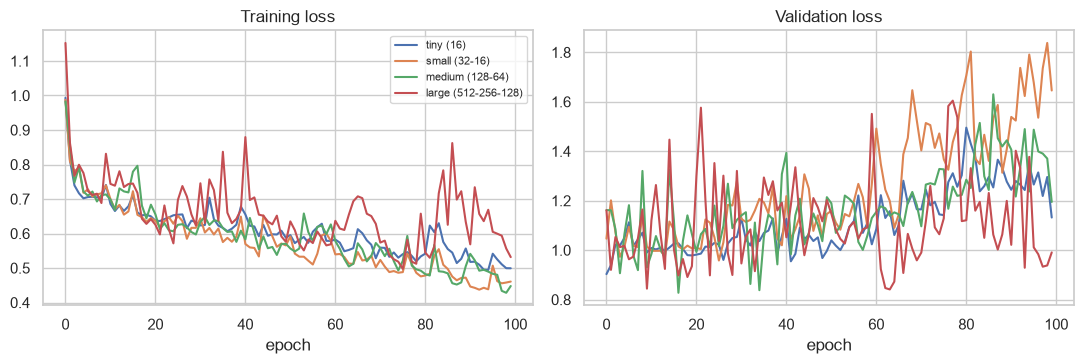

In [122]:
# (b) network capacity
capacities = {"tiny (16)": (16,), "small (32-16)": (32, 16), "medium (128-64)": (128, 64),
              "large (512-256-128)": (512, 256, 128)}
cap_results, cap_hists = [], {}
for name, hidden in capacities.items():
    m, h = fit_mlp(hidden=hidden, lr=best_lr)
    cap_hists[name] = h
    n_params = sum(p.numel() for p in m.parameters())
    cap_results.append({"architecture": name, "parameters": n_params, "final_train_acc": h["train_acc"][-1],
                        "final_train_loss": h["train_loss"][-1], "min_val_loss": min(h["val_loss"]),
                        "final_val_loss": h["val_loss"][-1], "best_epoch": h["best_epoch"], **{k: v for k, v in val_summary(m, h).items() if k != "train_acc"}})
cap_exp = pd.DataFrame(cap_results)
display(cap_exp.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, h in cap_hists.items():
    axes[0].plot(h["train_loss"], label=name); axes[1].plot(h["val_loss"], label=name)
axes[0].set(title="Training loss", xlabel="epoch"); axes[1].set(title="Validation loss", xlabel="epoch")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

#### Overfitting diagnosis
A model overfits when training loss keeps falling while validation loss reaches a minimum and then rises, i.e. when `final_val_loss` is clearly above `min_val_loss` and the best epoch is far before the last. The learning-curve plots above and the `best_epoch` / `min_val_loss` vs `final_val_loss` columns are the evidence; see the report at the end.

,regularisation,epochs run,best_epoch,min_val_loss,final_val_loss,train_acc,val_accuracy,val_balanced_accuracy,val_macro_f1
0,none,100,16,0.828,1.195,0.783,0.653,0.671,0.658
1,weight decay 1e-3,100,6,0.911,1.155,0.730,0.667,0.680,0.670
2,weight decay 1e-2,100,41,0.847,1.001,0.652,0.600,0.630,0.563
3,dropout 0.3,100,99,0.866,0.866,0.635,0.680,0.698,0.678
4,dropout 0.5,100,48,0.841,0.909,0.657,0.640,0.664,0.621
5,dropout 0.3 + wd 1e-3,100,50,0.895,1.121,0.643,0.627,0.653,0.613
6,early stopping (patience 10),14,3,0.907,0.968,0.613,0.613,0.632,0.615


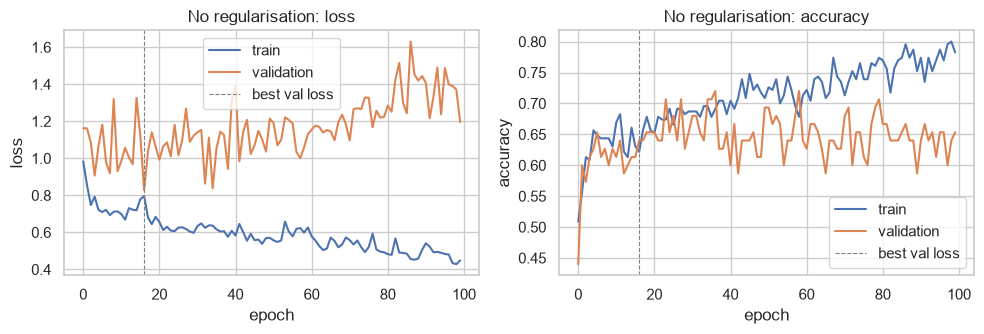

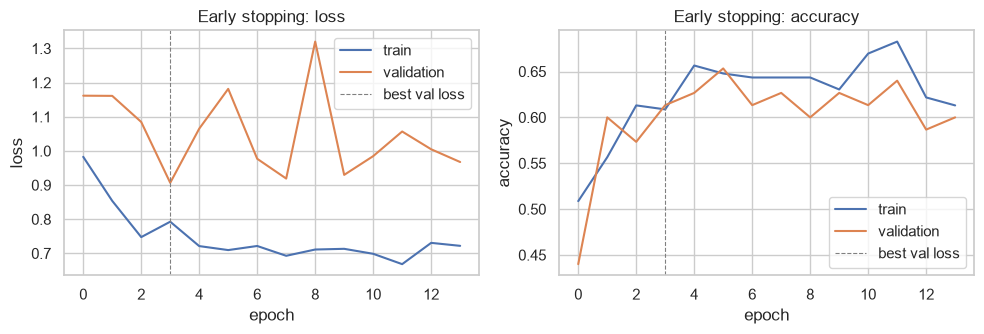

In [123]:
# (c) regularisation on the oversized-but-reasonable model, then (d) early stopping
BIG = (128, 64)
reg_configs = {
    "none": dict(),
    "weight decay 1e-3": dict(weight_decay=1e-3),
    "weight decay 1e-2": dict(weight_decay=1e-2),
    "dropout 0.3": dict(dropout=0.3),
    "dropout 0.5": dict(dropout=0.5),
    "dropout 0.3 + wd 1e-3": dict(dropout=0.3, weight_decay=1e-3),
    "early stopping (patience 10)": dict(patience=10),
}
reg_results, reg_hists = [], {}
for name, kw in reg_configs.items():
    m, h = fit_mlp(hidden=BIG, lr=best_lr, **kw)
    reg_hists[name] = (m, h)
    reg_results.append({"regularisation": name, "epochs run": len(h["train_loss"]), "best_epoch": h["best_epoch"],
                        "min_val_loss": min(h["val_loss"]), "final_val_loss": h["val_loss"][-1], **val_summary(m, h)})
reg_exp = pd.DataFrame(reg_results)
display(reg_exp.round(3))
plot_curves(reg_hists["none"][1], "No regularisation")
plot_curves(reg_hists["early stopping (patience 10)"][1], "Early stopping")

In [124]:
# Selection: best validation macro-F1 among the regularised/early-stopped candidates; ties broken by lower validation loss.
sel = reg_exp.sort_values(["val_macro_f1", "min_val_loss"], ascending=[False, True]).iloc[0]
print("Selected configuration:", sel["regularisation"], "| lr:", best_lr, "| hidden:", BIG)
final_mlp, final_hist = reg_hists[sel["regularisation"]]
display(sel.to_frame("selected").round(3))

Selected configuration: dropout 0.3 | lr: 0.01 | hidden: (128, 64)


,selected
regularisation,dropout 0.3
epochs run,100
best_epoch,99
min_val_loss,0.866393
final_val_loss,0.866393
train_acc,0.634783
val_accuracy,0.68
val_balanced_accuracy,0.697802
val_macro_f1,0.677778


### H.5 Classical comparison: logistic regression and XGBoost

XGBoost gets a small grid search scored **on the validation split only** (no cross-validation on the test partition).

In [125]:
import itertools

# PyTorch and XGBoost each ship their own OpenMP runtime; loading both in one process can crash the kernel on macOS
# ("OMP: Error #179"). XGBoost therefore runs in a separate worker process (joblib/loky) that never imports torch.
def xgb_fit_predict(params, X_fit, y_fit, w_fit, X_list):
    from xgboost import XGBClassifier
    model = XGBClassifier(**params, subsample=0.8, colsample_bytree=0.5, reg_lambda=1.0,
                          random_state=141026, n_jobs=1, eval_metric="mlogloss")
    model.fit(X_fit, y_fit, sample_weight=w_fit)
    return [model.predict(X_) for X_ in X_list]

sample_w = class_weights.numpy()[ytr_i]
xgb_grid = [dict(max_depth=d, learning_rate=eta, n_estimators=n)
            for d, eta, n in itertools.product([2, 3, 5], [0.05, 0.2], [100, 300])]
def run_xgb_isolated(param_sets, X_list):
    # n_jobs >= 2 forces real worker processes (n_jobs=1 would run inside this process)
    return Parallel(n_jobs=2, backend="loky")(
        delayed(xgb_fit_predict)(p, Xtr_s, ytr_i, sample_w, X_list) for p in param_sets)

xgb_val_preds = run_xgb_isolated(xgb_grid, [Xva_s])
xgb_table = pd.DataFrame([{**p, **{f"val_{k}": v for k, v in score(yva_i, pred[0]).items()}}
                          for p, pred in zip(xgb_grid, xgb_val_preds)])
xgb_table = xgb_table.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(xgb_table.head(6).round(3))
xgb_best = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in xgb_table.iloc[0][["max_depth", "learning_rate", "n_estimators"]].items()}
print("Selected XGBoost parameters (validation macro-F1):", xgb_best)

,max_depth,learning_rate,n_estimators,val_accuracy,val_balanced_accuracy,val_macro_f1
0,3,0.05,100,0.680,0.692,0.686
1,2,0.05,100,0.680,0.694,0.678
2,5,0.05,100,0.667,0.679,0.676
3,5,0.05,300,0.653,0.662,0.667
4,5,0.20,300,0.653,0.663,0.666
5,5,0.20,100,0.653,0.663,0.663


Selected XGBoost parameters (validation macro-F1): {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 100}


### H.6 Final evaluation on the untouched test partition

All three models were selected using validation data only. They are trained once (on the training partition) and evaluated once on the test partition.

,accuracy,balanced_accuracy,macro_f1
model,,,
Logistic regression,0.618,0.651,0.614
MLP (selected),0.618,0.656,0.608
XGBoost,0.592,0.628,0.569


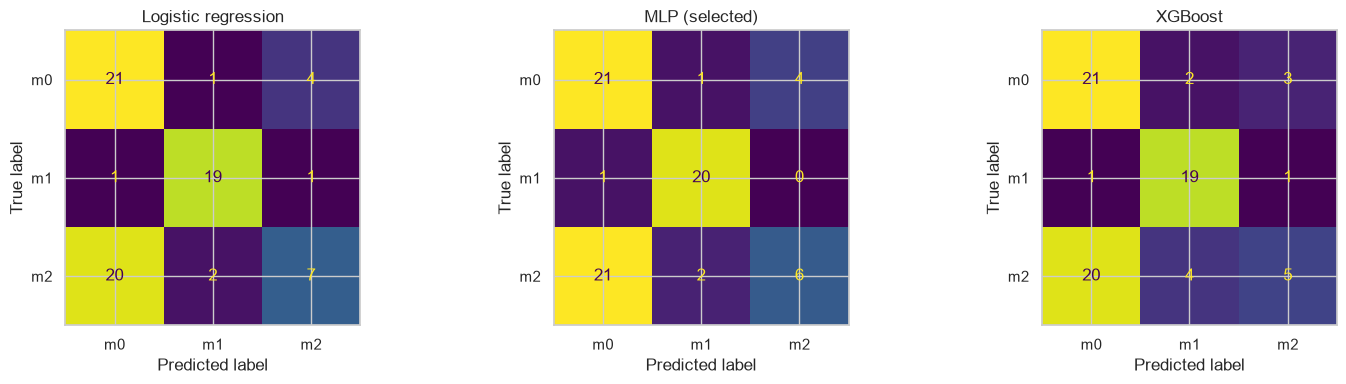

===== Logistic regression
         pred m0  pred m1  pred m2
true m0       21        1        4
true m1        1       19        1
true m2       20        2        7
              precision    recall  f1-score   support

          m0       0.50      0.81      0.62        26
          m1       0.86      0.90      0.88        21
          m2       0.58      0.24      0.34        29

    accuracy                           0.62        76
   macro avg       0.65      0.65      0.61        76
weighted avg       0.63      0.62      0.59        76

===== MLP (selected)
         pred m0  pred m1  pred m2
true m0       21        1        4
true m1        1       20        0
true m2       21        2        6
              precision    recall  f1-score   support

          m0       0.49      0.81      0.61        26
          m1       0.87      0.95      0.91        21
          m2       0.60      0.21      0.31        29

    accuracy                           0.62        76
   macro avg       0

In [126]:
final_models = {
    "Logistic regression": lambda X_: logreg.predict(X_),
    "MLP (selected)": lambda X_: predict(final_mlp, X_),
    "XGBoost": lambda X_: run_xgb_isolated([xgb_best], [X_])[0][0],
}
test_rows, test_preds = [], {}
for name, fn in final_models.items():
    pred = fn(Xte_s); test_preds[name] = pred
    test_rows.append({"model": name, **score(yte_i, pred)})
test_table = pd.DataFrame(test_rows).set_index("model")
display(test_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, test_preds.items()):
    ConfusionMatrixDisplay.from_predictions(yte_i, pred, display_labels=hw_classes, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
for name, pred in test_preds.items():
    print("=====", name)
    print(pd.DataFrame(confusion_matrix(yte_i, pred), index=[f"true {c}" for c in hw_classes], columns=[f"pred {c}" for c in hw_classes]))
    print(classification_report(yte_i, pred, target_names=hw_classes, zero_division=0))
print("Test objects per sample group (largest 8):")
print(hw_gte.value_counts().head(8).to_string())
m2_wrong = hw_gte[(yte_i == 2) & (test_preds["MLP (selected)"] != 2)]
print("Misclassified m2 objects (MLP) by sample group:"); print(m2_wrong.value_counts().to_string())

### H.7 Report: answers to the questions

*(Numbers are from one seeded run; the test set has only 76 objects from 17 sample groups, so differences of a few points between models are within noise.)*

**1. Did the embedding space show visible separation between cell types?** Only weakly. The silhouette of `cell_type` is 0.04 in the scaled 128-d space, 0.05 in PCA-2 and 0.07 in t-SNE-2, i.e. classes overlap heavily in the projections. Class `m1` is the most distinct, `m0` and `m2` overlap. The embeddings contain usable but not clean class information: supervised models reach about 0.65-0.70 balanced accuracy, far above chance (0.33).

**2. Best learning rate and architecture.** Learning rate (baseline 128-32-16-3 MLP, 100 epochs, Adam): 1e-5 and 1e-4 underfit (validation macro-F1 0.39 and 0.56), 1e-3 and 1e-2 were the best and nearly tied (0.654 and 0.656), 1e-1 was unstable (0.45). I chose **1e-2** by validation macro-F1 (min validation loss alone would wrongly favour 0.1, where the minimum is a brief dip before the loss diverges). Capacity at that rate: 16 units (0.624), 32-16 (0.656), **128-64 (0.658)**, 512-256-128 (0.619). Small and medium networks are indistinguishable on 75 validation objects; the largest is not better (211k parameters for 230 training objects). I used 128-64 as the base for the regularisation study.

**3. Did the MLP overfit?** Yes, without regularisation. For 128-64 the validation loss reaches its minimum (0.83) at epoch 16 and then rises to 1.20 while training accuracy keeps increasing (0.78); the same pattern holds for 32-16 at lr 1e-2 (minimum 0.96 at epoch 25, final 1.65). Training accuracy (0.78) is above validation accuracy (0.65).

**4. Most useful regularisation.** **Dropout 0.3** gave the best validation macro-F1 (0.678 vs 0.658 without regularisation) and, more importantly, the validation loss no longer rises (final 0.87 vs 1.20, best epoch 99). Weight decay 1e-3 helped little (final validation loss 1.16) and 1e-2 was too strong (0.563). Dropout 0.5 was a bit too strong (0.621). Early stopping with patience 10 stopped at epoch 14 and restored epoch 3: it prevents the loss increase but, with this noisy validation curve, stopped too early (0.615). Selected configuration: 128-64, lr 1e-2, dropout 0.3, 100 epochs.

**5. MLP vs logistic regression vs XGBoost.** On validation: logistic regression 0.668, MLP 0.678, XGBoost 0.686 macro-F1: all equal within noise. On the untouched test set: balanced accuracy 0.651 (logistic regression), 0.656 (MLP), 0.628 (XGBoost); macro-F1 0.614, 0.608, 0.569. The neural network did **not** clearly beat a regularised linear model; the gain does not justify the extra complexity. Embeddings are already a learned representation, so a linear classifier on top of them is a strong baseline, and 230 training objects are too few for the extra flexibility of an MLP or boosted trees to pay off.

**7. Which cell types were confused?** The dominant error is **`m2` predicted as `m0`**: the MLP classified 21 of 29 `m2` test objects as `m0` (logistic regression 20, XGBoost 20); `m2` recall is only 0.17-0.24 for all three models, while `m0` recall is 0.81 and `m1` recall 0.90-0.95. `m1` is rarely confused with anything. 13 of the 23 misclassified `m2` objects come from a single sample group (`sample_group_081`, all of whose test objects were misclassified), i.e. the errors are partly sample-level, not independent object-level mistakes; also the test performance depends heavily on a handful of groups.

**8. What would help explain the errors?** Per-sample metadata (staining batch, imaging session, acquisition settings, patient/donor, passage number) to check whether `sample_group_081` differs technically; the original images or segmentation masks of the confused `m0`/`m2` objects; object size and shape descriptors (the handcrafted features from the first part of the practical) combined with the embedding; more `m2` samples from distinct groups; and group-wise cross-validation over all 85 groups (instead of one split) to get a reliable estimate with confidence intervals.